# Exercício 04 — Identificação de fraturas em rocha com CNN

Este notebook apresenta a conversão para Python/PyTorch do laboratório
**Identifying Rock Crack by Convolutional Neural Network**, de Shihang Feng.
As rotinas de `CNN_lab.zip` estão adaptadas em `crack_cnn.py`; a configuração,
a execução e a coleta dos experimentos permanecem no notebook.

Para comparar os problemas binário e multiclasse a partir da mesma seleção manual,
optei por reutilizar `annotations_big.csv` e `annotations_small.csv`. Cada arquivo
contém 200 pontos de fratura e 200 de fundo. A concatenação dá origem a dois conjuntos
de 800 registros: no binário, as fraturas são reunidas em uma classe; no multiclasse,
as fraturas grandes e pequenas permanecem separadas.

Os experimentos estão organizados em blocos próprios, com modelos, configurações,
resumos e diretórios de saída separados. **Run All** executa os dois blocos quando
os CSVs estão disponíveis. Cada experimento é acompanhado de interpretação quantitativa e visual; a conclusão compara os dois problemas e sintetiza os resultados.

Referências: [laboratório oficial](http://utam.gg.utah.edu/Classes/ML/LAB1/Chapter.Book.CNN/Chapter.CNNCrack/lab.html),
seção 10.5 e apêndice 10.18 de *Machine Learning Methods in Geoscience*.

**Autor: Lucas Torres Marques**

## 1. Ambiente e configuração

A execução utiliza o kernel **Python (exercise04 — AMD ROCm)**. No WSL, o ajuste do
profiler é aplicado antes de importar o PyTorch. `DEVICE = "auto"` seleciona a GPU
quando disponível; a interface `torch.cuda` também é utilizada para GPUs AMD.

Os resultados são gravados em `results/main/` e podem ser sobrescritos nas próximas
execuções. Os CSVs originais de anotação são somente lidos. Não há seleção adicional
para multiclasse: seus rótulos são derivados dos mesmos arquivos usados no binário.

`INFERENCE_STRIDE = 1` classifica todos os 446.489 pixels. Valores como `16` ou `32`
produzem uma prévia em grade reduzida e não alteram os conjuntos de treinamento.

In [ ]:
from pathlib import Path
from dataclasses import replace
from hashlib import sha256
import json
import importlib
import os
import platform
import sys

# Deve preceder a importação do PyTorch para evitar a falha do profiler no WSL.
if "microsoft" in platform.release().lower():
    os.environ["ROCPROFILER_REGISTER_ENABLED"] = "0"

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import numpy as np
import pandas as pd
from PIL import Image
import torch
from IPython.display import display

EXERCISE_DIR = Path.cwd()
if not (EXERCISE_DIR / "crack_cnn.py").is_file():
    EXERCISE_DIR = EXERCISE_DIR / "exercise04"
EXERCISE_DIR = EXERCISE_DIR.resolve()
if not (EXERCISE_DIR / "crack_cnn.py").is_file():
    raise FileNotFoundError("Abra o notebook em exercise04/ ou na raiz do repositório.")
sys.path.insert(0, str(EXERCISE_DIR))

# Recarrega as rotinas locais para reconhecer alterações sem usar o módulo antigo do kernel.
importlib.invalidate_caches()
import crack_cnn as _crack_cnn
importlib.reload(_crack_cnn)

from crack_cnn import (
    BINARY_CLASSES, MULTICLASS_CLASSES, LAB_URL, ZIP_SHA256,
    TrainConfig, PatchExtractor, load_lab_data, read_annotations,
    build_annotation_datasets, split_by_center, train_cnn,
    classification_metrics, classify_image, export_run,
)
from annotation_picker import AnnotationPicker

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10, "axes.labelsize": 9})
pd.options.display.float_format = "{:.6g}".format

RANDOM_SEED = 0
SPLIT_SEED = 42
REFERENCE_EPOCHS = 10
LONG_EPOCHS = 100
TRAIN_BATCH_SIZE = 20
INFERENCE_BATCH_SIZE = 512
INFERENCE_STRIDE = 1
VALIDATION_FRACTION = 0.2
DEVICE = "auto"  # "auto", "cpu" ou "cuda" (inclusive AMD/ROCm)
CPU_THREADS = min(4, os.cpu_count() or 1)
torch.set_num_threads(CPU_THREADS)
device = torch.device("cuda" if DEVICE == "auto" and torch.cuda.is_available()
                      else "cpu" if DEVICE == "auto" else DEVICE)

SOURCE_COUNTS = {0: 200, 1: 200}
ANNOTATION_PATHS = {
    "big": EXERCISE_DIR / "annotations_big.csv",
    "small": EXERCISE_DIR / "annotations_small.csv",
}
RUN_DIR = EXERCISE_DIR / "results" / "main"
RUN_DIR.mkdir(parents=True, exist_ok=True)
settings = {
    "tasks": ["binary", "multiclass"],
    "annotation_sources": {key: path.name for key, path in ANNOTATION_PATHS.items()},
    "binary_counts": {0: 400, 1: 400}, "multiclass_counts": {0: 400, 1: 200, 2: 200},
    "random_seed": RANDOM_SEED, "split_seed": SPLIT_SEED,
    "reference_epochs": REFERENCE_EPOCHS, "long_epochs": LONG_EPOCHS,
    "train_batch_size": TRAIN_BATCH_SIZE, "inference_batch_size": INFERENCE_BATCH_SIZE,
    "inference_stride": INFERENCE_STRIDE, "validation_fraction": VALIDATION_FRACTION,
    "device": str(device), "cpu_threads": CPU_THREADS,
    "lab_url": LAB_URL, "zip_sha256": ZIP_SHA256,
}
(RUN_DIR / "settings.json").write_text(json.dumps(settings, indent=2), encoding="utf-8")
print(f"Python: {sys.version.split()[0]} | PyTorch: {torch.__version__} | dispositivo: {device}")
print(f"ROCm: {torch.version.hip} | CUDA: {torch.version.cuda}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(device)}")
print(f"Resultados: {RUN_DIR}")

Python: 3.12.16 | PyTorch: 2.13.0+rocm7.2 | dispositivo: cuda
ROCm: 7.2.53211 | CUDA: None
GPU: AMD Radeon RX 9070 XT
Resultados: /mnt/c/Users/Lucas Torres/Documents/Acadêmico/Doutorado/Tópicos Especiais em Processamento Inteligente da Informação/exercise04/results/main


## 2. Imagem e correspondência com o MATLAB

A imagem é lida do pacote oficial armazenado em `.cache/CNN_lab.zip`, cujo SHA-256
é verificado antes do uso. Os pontos fornecidos no MATLAB são carregados apenas
para consulta; os experimentos deste roteiro utilizam a seleção manual existente.
Como a imagem já contém valores em $[-1,1]$, optei por preservar essa escala.

| MATLAB | Python | Convenção |
|---|---|---|
| `padimage.m` | `PatchExtractor` | replicação da borda |
| `interp2` | interpolação bilinear com `align_corners=True` | $17\times17\rightarrow32\times32$ |
| `cnnsetup.m` | `CrackCNN` | inicialização Xavier uniforme e bias zero |
| `cnnff.m` | `CrackCNN.forward` | convolução válida, sigmoide e pooling por média |
| `cnnbp.m` | `matlab_loss` + autograd | $\frac{1}{2N}\sum_{i,k}(a_{ik}-y_{ik})^2$ |
| `cnnapplygrads.m`, `cnntrain.m` | `train_cnn` | SGD, passo 1 e lotes de 20 |

Para manter a fidelidade ao código, preservei o pooling por média, a inversão espacial
dos kernels de `convn`, a vetorização por colunas e as saídas sigmoides. Os escores
são independentes e não precisam somar 1. A decisão utiliza o maior escore.
Os índices Python começam em zero: `x` representa coluna e `z`, linha.
As sementes são fixas, mas as sequências aleatórias e a precisão numérica diferem
do MATLAB: a conversão utiliza float32.

In [3]:
image, official_annotations = load_lab_data(EXERCISE_DIR / ".cache")
extractor = PatchExtractor(image)
print(f"Imagem: {image.shape}; intervalo: [{image.min():g}, {image.max():g}]")


def plot_annotations(table, classes, title, destination):
    fig, ax = plt.subplots(figsize=(13, 6), constrained_layout=True)
    ax.imshow(image, cmap="gray", vmin=-1, vmax=1)
    colors = ["deepskyblue", "gold", "#ff4b82"]
    for label, name in classes.items():
        selected = table[table.label == label]
        ax.scatter(selected.x, selected.z, s=22, facecolors="none", edgecolors=colors[label],
                   linewidths=0.9, label=f"{name}: {len(selected)}")
    ax.set(title=title, xlabel="x (pixel)", ylabel="z (pixel)")
    ax.legend()
    ax.grid(False)
    fig.savefig(destination, dpi=160)
    plt.show()


def plot_patch_examples(table, classes, destination):
    patches = extractor.from_annotations(table)
    fig, axes = plt.subplots(len(classes), 6, figsize=(11, 2 * len(classes)),
                             squeeze=False, constrained_layout=True)
    for row, (label, name) in enumerate(classes.items()):
        indices = np.flatnonzero(table.label.to_numpy() == label)[:6]
        for ax, index in zip(axes[row], indices):
            ax.imshow(patches[index, 0], cmap="gray", vmin=-1, vmax=1)
            point = table.iloc[index]
            ax.set_title(f"{name}\n({point.x}, {point.z})")
            ax.axis("off")
    fig.savefig(destination, dpi=160)
    plt.show()

Imagem: (457, 977); intervalo: [-1, 1]


## 3. Reutilização do picking e composição dos conjuntos

Esta seção verifica `annotations_big.csv` e `annotations_small.csv`. Quando existem,
os arquivos são validados e seus pontos são apresentados sobre a imagem, sem abrir
o picker. O anotador é exibido somente se algum CSV estiver ausente. Um arquivo
existente nunca é substituído pelo anotador.

Na composição dos dados, os dois fundos são concatenados. No problema binário,
as duas seleções de fratura recebem o rótulo 1. No multiclasse, as fraturas de
`big` recebem 1 e as de `small`, 2. Não há novo picking nem exclusão de registros.

| Conjunto | Fundo (0) | Fratura/grande (1) | Pequena (2) | Total |
|---|---:|---:|---:|---:|
| `annotations_big.csv` | 200 | 200 | — | 400 |
| `annotations_small.csv` | 200 | 200 | — | 400 |
| Binário combinado | 400 | 400 | — | 800 |
| Multiclasse combinado | 400 | 200 | 200 | 800 |

Os conjuntos derivados são gravados somente em `results/main/datasets/`.
As colunas `source` e `source_row` identificam a origem de cada registro.

annotations_big.csv: 400 registros carregados; arquivo preservado.


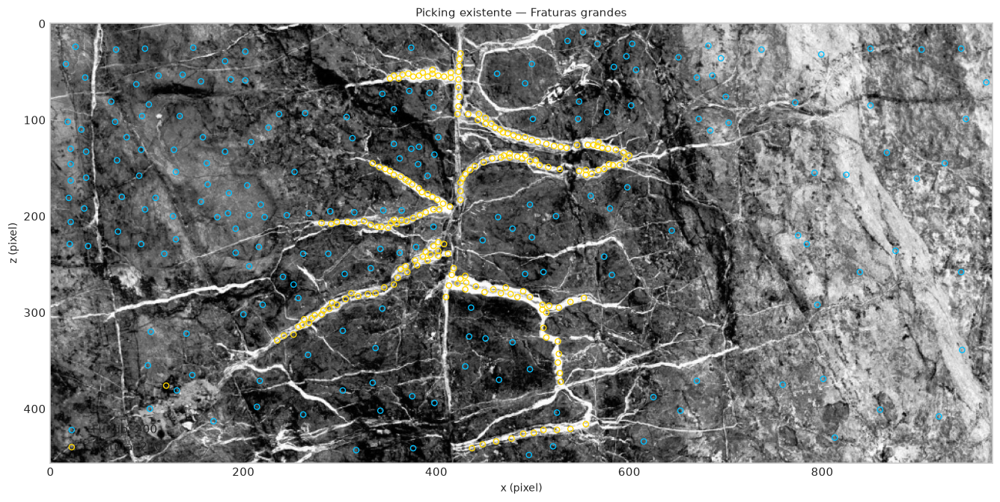

annotations_small.csv: 400 registros carregados; arquivo preservado.


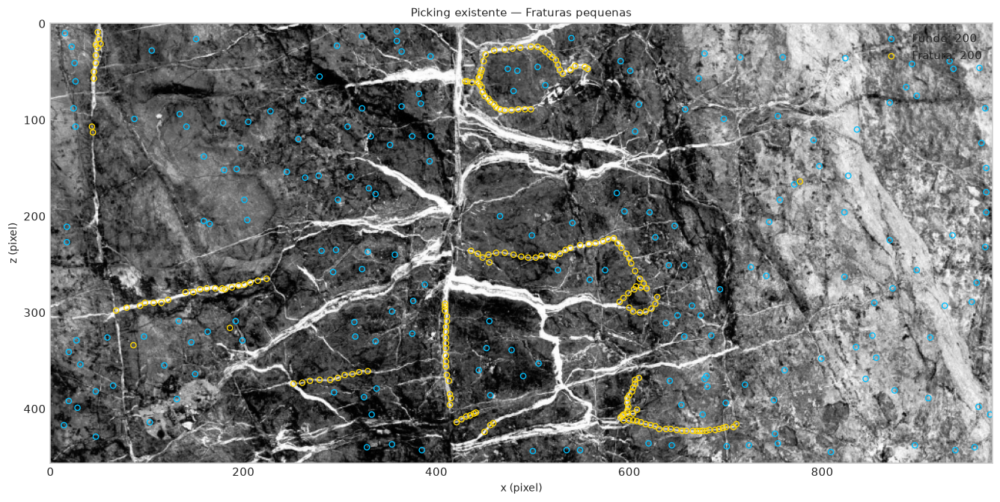

In [4]:
manual_sets = {}
pickers = {}
annotation_hashes = {}
for key, path in ANNOTATION_PATHS.items():
    title = "Fraturas grandes" if key == "big" else "Fraturas pequenas"
    if path.exists():
        table = read_annotations(path, image.shape, BINARY_CLASSES, SOURCE_COUNTS)
        manual_sets[key] = table
        annotation_hashes[key] = sha256(path.read_bytes()).hexdigest()
        print(f"{path.name}: {len(table)} registros carregados; arquivo preservado.")
        plot_annotations(table, BINARY_CLASSES, f"Picking existente — {title}",
                         RUN_DIR / f"picking_{key}.png")
    else:
        print(f"{path.name} ausente: selecione 200 fraturas e 200 fundos e salve o CSV.")
        picker = AnnotationPicker(image, path, BINARY_CLASSES, SOURCE_COUNTS, order=(1, 0))
        pickers[key] = picker
        picker.show()

In [5]:
# Apenas leitura dos CSVs de origem. Mesmo após uma seleção inicial, não há sobrescrita.
for key, path in ANNOTATION_PATHS.items():
    if key not in manual_sets:
        manual_sets[key] = read_annotations(path, image.shape, BINARY_CLASSES, SOURCE_COUNTS)
        annotation_hashes[key] = sha256(path.read_bytes()).hexdigest()

combined_binary, combined_multiclass = build_annotation_datasets(
    manual_sets["big"], manual_sets["small"], image.shape
)
DATASETS_DIR = RUN_DIR / "datasets"
DATASETS_DIR.mkdir(parents=True, exist_ok=True)
combined_binary.to_csv(DATASETS_DIR / "annotations_binary.csv", index=False)
combined_multiclass.to_csv(DATASETS_DIR / "annotations_multiclass.csv", index=False)
settings["annotation_sha256"] = annotation_hashes
(RUN_DIR / "settings.json").write_text(json.dumps(settings, indent=2), encoding="utf-8")
counts = pd.DataFrame({
    "Binário": combined_binary.label.value_counts().sort_index(),
    "Multiclasse": combined_multiclass.label.value_counts().sort_index(),
}).fillna(0).astype(int)
counts.index.name = "label"
display(counts)
assert len(combined_binary) == len(combined_multiclass) == 800
assert np.array_equal(combined_binary.label.to_numpy(),
                      (combined_multiclass.label.to_numpy() > 0).astype(int))
print("Conjuntos derivados prontos. Nenhum CSV original foi alterado.")

,Binário,Multiclasse
label,,
0,400,400
1,400,200
2,0,200


Conjuntos derivados prontos. Nenhum CSV original foi alterado.


## 4. Rotinas compartilhadas de execução e exportação

Os blocos binário e multiclasse compartilham somente a imagem, a extração dos recortes
e as rotinas de treinamento e visualização. Cada bloco inicializa seus próprios
dados, configurações e registro de resultados; nenhum modelo treinado no bloco
binário é reutilizado pelo multiclasse.

A CNN utiliza duas convoluções $5\times5$, sigmoides e pooling médio $2\times2$.
Na configuração base, os 300 atributos finais alimentam duas ou três saídas.
A classificação da imagem é realizada em lotes para limitar o uso de memória.
Cada experimento salva curvas, métricas por classe, matrizes de confusão, modelos,
anotações utilizadas e mapas com seus escores.

A validação separa cerca de 20% dos centros únicos por classe. Todas as repetições
de um centro permanecem no mesmo subconjunto. Recortes próximos ainda podem se
sobrepor; essa divisão corresponde a uma validação interna da mesma imagem.
Não há máscara de referência para avaliar todos os pixels. A distribuição dos
rótulos no mapa é descritiva, e os escores sigmoides não são probabilidades calibradas.

In [6]:
def save_section_summary(registry, directory, show=True):
    summary = pd.concat([run["summary"] for run in registry.values()], ignore_index=True)
    distribution = pd.concat([
        run["distribution"].assign(task=directory.name) for run in registry.values()
    ], ignore_index=True)
    summary.to_csv(directory / "summary.csv", index=False)
    distribution.to_csv(directory / "map_summary.csv", index=False)
    if show:
        display(summary)
        display(distribution)
    return summary, distribution


def run_experiment(name, annotations, config, *, classes, output_dir, registry, split=False):
    data = extractor.from_annotations(annotations)
    target = annotations.label.to_numpy()
    if split:
        training_index, validation_index = split_by_center(
            annotations, VALIDATION_FRACTION, SPLIT_SEED
        )
        validation = (data[validation_index], target[validation_index])
    else:
        training_index = np.arange(len(annotations))
        validation_index = np.array([], dtype=int)
        validation = None
    print(f"\n{name}: {len(training_index)} treino / {len(validation_index)} validação")
    result = train_cnn(data[training_index], target[training_index], config, device, validation)
    metrics = [classification_metrics(result.model, data[training_index],
                                      target[training_index], classes, "training")]
    if split:
        metrics.append(classification_metrics(result.model, data[validation_index],
                                              target[validation_index], classes, "validation"))
    directory = output_dir / name
    export_run(directory, result, annotations, training_index, validation_index, classes, metrics)

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)
    for prefix, title in [("train", "Treino"), ("validation", "Validação")]:
        if f"{prefix}_loss" in result.history:
            axes[0].plot(result.history.epoch, result.history[f"{prefix}_loss"], label=title)
            axes[1].plot(result.history.epoch, result.history[f"{prefix}_accuracy"], label=title)
    for ax in axes:
        ax.axvline(result.selected_epoch, color="gray", linestyle="--", alpha=0.6,
                   label=f"Modelo salvo: época {result.selected_epoch}")
        ax.set(xlabel="Época")
        ax.legend(fontsize=8)
    axes[0].set(title=f"{name} — perda", ylabel="1/(2N) × soma dos erros quadráticos")
    axes[1].set(title=f"{name} — acurácia", ylabel="Fração de acertos", ylim=(-0.02, 1.02))
    fig.savefig(directory / "learning_curves.png", dpi=160)
    plt.show()

    fig, axes = plt.subplots(1, len(metrics), figsize=(4.5 * len(metrics), 4), squeeze=False,
                             constrained_layout=True)
    for ax, (summary, per_class, matrix) in zip(axes[0], metrics):
        ax.imshow(matrix, cmap="Blues")
        for (row, col), value in np.ndenumerate(matrix.to_numpy()):
            ax.text(col, row, str(value), ha="center", va="center",
                    color="white" if value > matrix.to_numpy().max() / 2 else "black")
        ax.set(xticks=range(len(classes)), yticks=range(len(classes)),
               xticklabels=list(classes.values()), yticklabels=list(classes.values()),
               xlabel="Classe prevista", ylabel="Classe anotada",
               title=str(summary.iloc[0]["subset"]))
        ax.grid(False)
        ax.tick_params(axis="x", labelrotation=25)
    fig.savefig(directory / "confusion_matrices.png", dpi=160)
    plt.show()

    labels, scores, x_axis, z_axis, prediction_seconds = classify_image(
        result.model, extractor, INFERENCE_BATCH_SIZE, INFERENCE_STRIDE
    )
    np.savez_compressed(directory / "maps.npz", labels=labels, scores=scores,
                        x=x_axis, z=z_axis, class_ids=np.array(list(classes)),
                        image_shape=np.array(image.shape), stride=INFERENCE_STRIDE)
    Image.fromarray(labels).save(directory / "labels.png")
    colors = ["#154360", "#f1c40f", "#e74c3c"][:len(classes)]
    cmap = ListedColormap(colors)
    norm = BoundaryNorm(np.arange(len(classes) + 1) - 0.5, len(classes))
    extent = (x_axis[0] - INFERENCE_STRIDE / 2, x_axis[-1] + INFERENCE_STRIDE / 2,
              z_axis[-1] + INFERENCE_STRIDE / 2, z_axis[0] - INFERENCE_STRIDE / 2)
    sampled_image = image[np.ix_(z_axis, x_axis)]
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), constrained_layout=True)
    axes[0].imshow(sampled_image, cmap="gray", vmin=-1, vmax=1, extent=extent)
    mapped = axes[1].imshow(labels, cmap=cmap, norm=norm, interpolation="nearest", extent=extent)
    axes[2].imshow(sampled_image, cmap="gray", vmin=-1, vmax=1, extent=extent)
    axes[2].imshow(np.ma.masked_where(labels == 0, labels), cmap=cmap, norm=norm,
                   interpolation="nearest", extent=extent, alpha=0.65)
    suffix = "" if INFERENCE_STRIDE == 1 else f" (prévia, stride {INFERENCE_STRIDE})"
    for ax, title in zip(axes, ("Imagem", "Classes", "Fraturas sobre a imagem")):
        ax.set(title=f"{title}{suffix}", xlabel="x (pixel)", ylabel="z (pixel)")
        ax.grid(False)
    colorbar = fig.colorbar(mapped, ax=axes[1], ticks=range(len(classes)), shrink=0.75)
    colorbar.ax.set_yticklabels(list(classes.values()))
    fig.suptitle(name)
    fig.savefig(directory / "classification.png", dpi=160)
    plt.show()

    fig, axes = plt.subplots(1, len(classes), figsize=(6 * len(classes), 4),
                             constrained_layout=True, squeeze=False)
    for ax, (label, class_name) in zip(axes[0], classes.items()):
        mapped = ax.imshow(scores[:, :, label], cmap="viridis", vmin=0, vmax=1, extent=extent)
        ax.set(title=f"Escore sigmoide — {class_name}", xlabel="x (pixel)", ylabel="z (pixel)")
        ax.grid(False)
        fig.colorbar(mapped, ax=ax, shrink=0.8)
    fig.savefig(directory / "scores.png", dpi=160)
    plt.show()

    summary = pd.concat([m[0] for m in metrics], ignore_index=True).assign(
        task=output_dir.name, experiment=name, parameters=sum(p.numel() for p in result.model.parameters()),
        epochs_run=len(result.history), selected_epoch=result.selected_epoch,
        train_seconds=result.seconds, inference_seconds=prediction_seconds,
        inference_stride=INFERENCE_STRIDE,
    )
    distribution = pd.DataFrame([{
        "experiment": name, "label": label, "class": class_name,
        "centers": int(np.sum(labels == label)), "fraction": float(np.mean(labels == label)),
        "inference_stride": INFERENCE_STRIDE,
    } for label, class_name in classes.items()])
    distribution.to_csv(directory / "map_distribution.csv", index=False)
    registry[name] = {"training": result, "labels": labels, "scores": scores,
                     "classes": classes, "summary": summary, "directory": directory, "distribution": distribution}
    display(summary)
    display(pd.concat([m[1] for m in metrics], ignore_index=True))
    display(distribution)
    save_section_summary(registry, output_dir, show=False)
    return result

### 4.1. Critérios de interpretação e limites da avaliação

A análise considera os **12 experimentos desta execução**, registrados em
`results/main/binary/` e `results/main/multiclass/`, com os mesmos 800 centros,
sementes 0 e 42, stride 1 e GPU RX 9070 XT. Os experimentos de picking isolado
usam 400 pontos cada. Os valores narrados correspondem a essas saídas;
uma nova execução pode exigir atualização do texto, principalmente dos tempos.

Para a leitura qualitativa, adotei critérios compatíveis com a formação em
Machine Learning: correspondência com os traços visíveis, continuidade,
largura aparente, recuperação de ramificações e supressão de textura do fundo.
*Visualmente plausível* indica compatibilidade com a imagem, sem validação
geológica especializada. Fora das anotações, falsos positivos e negativos
são hipóteses de inspeção visual, pois não há máscara completa de referência.

Nas matrizes, **linhas representam a classe verdadeira e colunas, a prevista**.
No binário, falso positivo preserva fundo como fratura; falso negativo omite
uma fratura anotada. No multiclasse, trocar grande/pequena é diferente de
falhar na detecção. As tabelas apresentam métricas por classe e médias macro,
que atribuem o mesmo peso a cada classe, independentemente do suporte.

A perda é $L=(2N)^{-1}\sum_{i,k}(a_{ik}-y_{ik})^2$, sem raiz, avaliada ao
final de cada época. `rL` suaviza perdas de minibatches durante as atualizações.
Os valores absolutos de perda de duas e três saídas não são diretamente
comparáveis. Com parada antecipada, as métricas se referem à época restaurada,
que pode ser diferente da última época exibida na curva.

Como diagnóstico, a margem é a diferença entre os dois maiores escores.
A proporção de pixels com margem menor que 0,1 descreve proximidade das
saídas; não altera decisões, não calibra probabilidades e não identifica
automaticamente erros. As análises regionais usam faixas de coluna fixas:
esquerda `x<320`, centro `320≤x<700` e direita `x≥700`.

A seção 7.1 reproduz os diagnósticos a partir dos arquivos salvos, sem treinar
novamente. Os tempos são medições únicas, sem aquecimento padronizado nem
intervalos de variabilidade. Diferenças pequenas não estabelecem superioridade
computacional, e uma única semente não demonstra vantagem estatística.

## 5. Classificação binária

Este bloco utiliza o conjunto combinado com **400 pontos de fundo e 400 de fratura**.
As duas seleções de fratura pertencem à mesma classe. Além do conjunto completo,
a questão 1 mantém dois experimentos separados, com os 400 registros de `big`
e os 400 de `small`, para comparar o efeito da seleção das amostras.

Todos os resultados deste bloco são gravados em `results/main/binary/`.
As subseções podem ser executadas após a preparação comum, sem executar o bloco multiclasse.

,Amostras
label,
0,400
1,400


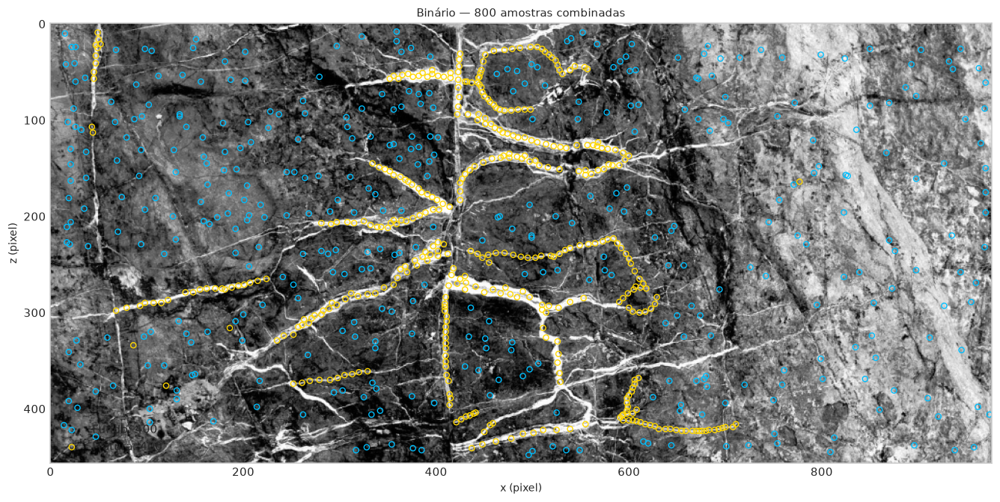

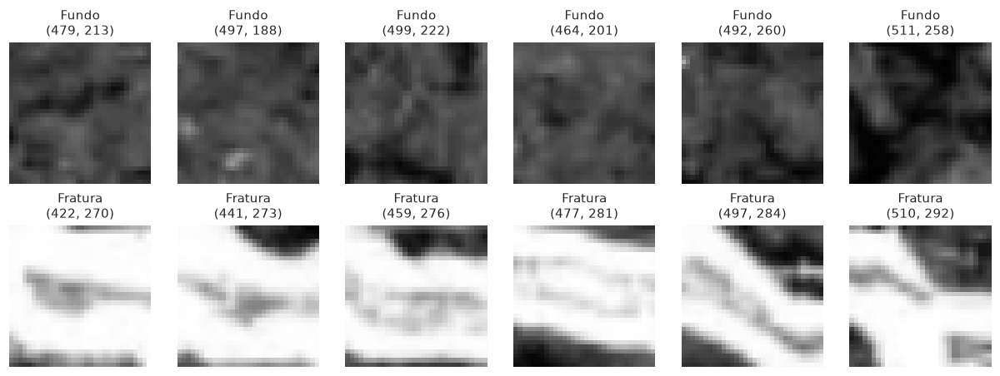

In [7]:
binary_dir = RUN_DIR / "binary"
binary_dir.mkdir(parents=True, exist_ok=True)
binary_results = {}
binary_annotations = combined_binary.copy(deep=True)
binary_annotations.to_csv(binary_dir / "dataset.csv", index=False)
binary_config = TrainConfig(epochs=REFERENCE_EPOCHS, batch_size=TRAIN_BATCH_SIZE,
                            learning_rate=1.0, channels=(6, 12), kernel_size=5, seed=RANDOM_SEED)


def run_binary(name, annotations=None, config=None, split=False):
    return run_experiment(
        name, binary_annotations if annotations is None else annotations,
        binary_config if config is None else config, classes=BINARY_CLASSES,
        output_dir=binary_dir, registry=binary_results, split=split,
    )


display(binary_annotations.groupby("label").size().rename("Amostras").to_frame())
plot_annotations(binary_annotations, BINARY_CLASSES, "Binário — 800 amostras combinadas",
                 binary_dir / "annotations.png")
plot_patch_examples(binary_annotations, BINARY_CLASSES, binary_dir / "patch_examples.png")

### 5.1. Configuração base — 10 épocas

A arquitetura e o treinamento seguem o código MATLAB: canais `(6, 12)`, kernels
`5 × 5`, pooling médio, passo 1, lotes de 20 e 10 épocas. O conjunto de 800 pontos
é uma adaptação à seleção manual combinada. O treinamento utiliza todas as entradas,
sem validação, totalizando 400 atualizações. O registro `rL` permite consultar
a média móvel da perda por minibatch, como em `cnntrain.m`.


reference_10epochs: 800 treino / 0 validação
Época   1/10 | loss=0.163046 | acurácia=0.761
Época  10/10 | loss=0.074061 | acurácia=0.902


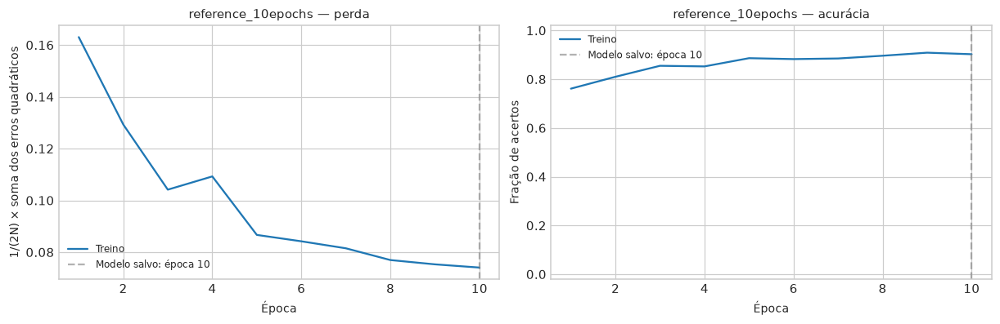

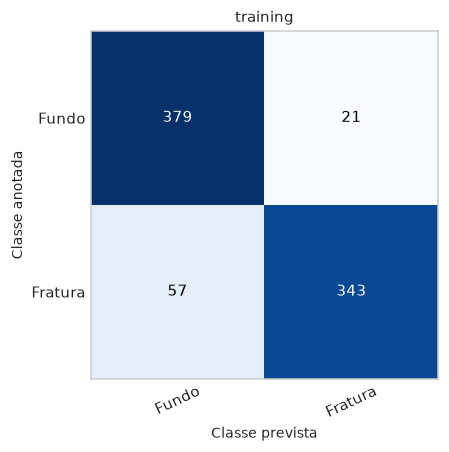

Classificação: 512/446,489 centros
Classificação: 89,600/446,489 centros
Classificação: 178,688/446,489 centros
Classificação: 267,776/446,489 centros
Classificação: 356,864/446,489 centros
Classificação: 445,952/446,489 centros
Classificação: 446,489/446,489 centros


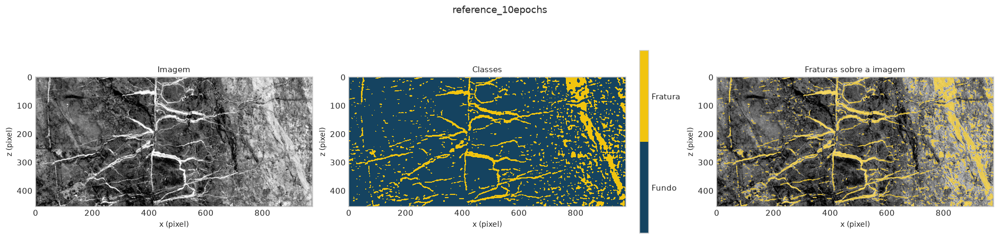

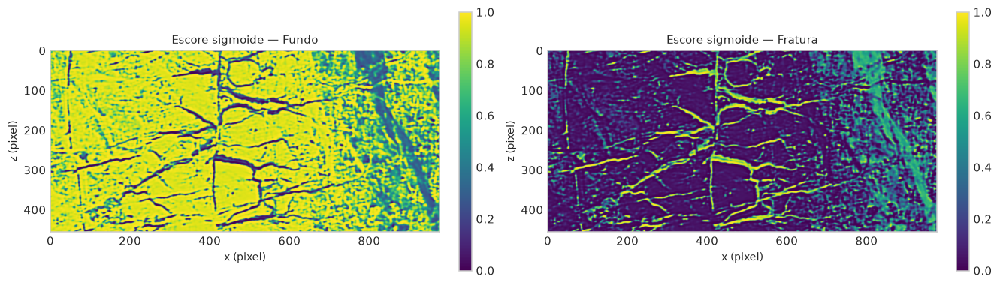

,subset,samples,loss,accuracy,precision_macro,recall_macro,f1_macro,task,experiment,parameters,epochs_run,selected_epoch,train_seconds,inference_seconds,inference_stride
0,training,800,0.0740609,0.9025,0.905787,0.9025,0.902302,binary,reference_10epochs,2570,10,10,1.32418,2.40139,1


,subset,label,class,support,precision,recall,f1
0,training,0,Fundo,400,0.869266,0.9475,0.906699
1,training,1,Fratura,400,0.942308,0.8575,0.897906


,experiment,label,class,centers,fraction,inference_stride
0,reference_10epochs,0,Fundo,375093,0.840095,1
1,reference_10epochs,1,Fratura,71396,0.159905,1


CrackCNN(
  (features): Sequential(
    (0): MatlabConv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
    (1): Sigmoid()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): MatlabConv2d(6, 12, kernel_size=(5, 5), stride=(1, 1))
    (4): Sigmoid()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
  )
  (classifier): Linear(in_features=300, out_features=2, bias=True)
)
Parâmetros: 2570


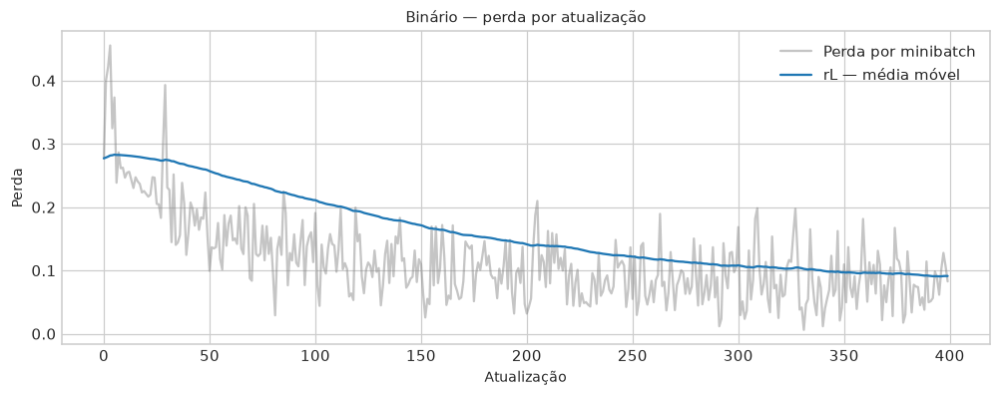

In [8]:
binary_reference = run_binary("reference_10epochs")
print(binary_reference.model)
print(f"Parâmetros: {sum(p.numel() for p in binary_reference.model.parameters())}")
fig, ax = plt.subplots(figsize=(9, 3.5), constrained_layout=True)
ax.plot(binary_reference.batches.loss, color="gray", alpha=0.45, label="Perda por minibatch")
ax.plot(binary_reference.batches.rL, label="rL — média móvel")
ax.set(title="Binário — perda por atualização", xlabel="Atualização", ylabel="Perda")
ax.legend()
fig.savefig(binary_dir / "reference_10epochs" / "matlab_rL.png", dpi=160)
plt.show()

#### 5.1.1. Interpretação — configuração binária base

A perda ao final da época diminui de **0,163046 na época 1 para 0,074061 na época 10**, enquanto a acurácia passa de 76,13% para **90,25%**, correspondendo a 722 acertos em 800 exemplos. A elevação da perda na época 4 não altera a tendência geral de aprendizado. A média móvel `rL` termina em 0,091200, acima da perda final, pois incorpora perdas de minibatches anteriores e não avalia exclusivamente os pesos finais.

| Subconjunto | Classe | n | Precisão (%) | Recall (%) | F1 (%) |
|---|---|---:|---:|---:|---:|
| Treino | Fundo | 400 | 86,93 | 94,75 | 90,67 |
| Treino | Fratura | 400 | 94,23 | 85,75 | 89,79 |
| Treino | **Média macro** | 800 | **90,58** | **90,25** | **90,23** |

A matriz de confusão contém **379 fundos corretamente classificados, 21 falsos positivos, 57 falsos negativos e 343 fraturas corretamente identificadas**. O erro predominante é a omissão de fraturas: 14,25% dos exemplos positivos são classificados como fundo, enquanto apenas 5,25% dos fundos são classificados como fratura. A precisão de 94,23% indica que a maioria das detecções positivas está correta nos exemplos avaliados, mas o recall de 85,75% revela que parte das estruturas de interesse permanece sem identificação. O F1 da classe fratura é 89,79%, enquanto o F1 macro alcança 90,23%.

**Além disso, sob a perspectiva geofísica, a predominância de falsos negativos merece atenção especial.** Em aplicações de interpretação estrutural, fraturas e descontinuidades podem estar associadas a zonas preferenciais de fluxo, alterações de permeabilidade e compartimentação de reservatórios. Consequentemente, **deixar de identificar essas estruturas pode comprometer a caracterização geológica e a avaliação da conectividade do meio**. Embora falsos positivos também sejam indesejáveis, pois podem sugerir descontinuidades inexistentes e induzir interpretações equivocadas, em uma etapa inicial de detecção costuma ser preferível preservar a sensibilidade do modelo, permitindo que possíveis estruturas sejam posteriormente verificadas pelo intérprete. Essa prioridade, entretanto, depende do objetivo da análise e dos custos associados a cada tipo de erro.

O mapa de classificação identifica **71.396 pixels (15,99%)** como fratura. Visualmente, o resultado apresenta coerência parcial com a interpretação esperada: a CNN destaca traços claros e contínuos na região central, mas também interrompe estruturas mais finas e atribui a classe fratura a determinadas texturas do fundo. Do ponto de vista geológico, a continuidade espacial é uma característica importante na interpretação de estruturas lineares, de modo que a fragmentação dessas feições pode dificultar a identificação de sua extensão, orientação e possível conectividade. É importante observar, contudo, que a continuidade visual não comprova, isoladamente, a existência de uma fratura.

Na região direita da imagem, `x ≥ 700`, **26,05% dos pixels são classificados como fratura**, incluindo áreas de aparência predominantemente textural. **Esse comportamento sugere uma possível confusão entre feições estruturais e padrões locais de intensidade ou textura**. Em imagens geofísicas, contrastes litológicos, ruídos e artefatos de aquisição ou processamento podem produzir respostas visualmente semelhantes às descontinuidades de interesse. Assim, a classificação não deve depender apenas de contrastes locais, mas também da geometria, orientação e coerência espacial das estruturas. Os padrões observados sugerem falsos positivos fora das anotações, embora a ausência de referência para toda a imagem impeça quantificar esses erros.

Os mapas de escores mostram respostas elevadas tanto nos traços centrais quanto na textura da região direita. Em **3,78% da imagem**, a diferença entre os dois maiores escores é inferior a 0,1, indicando decisões próximas da fronteira de classificação. Entretanto, uma margem elevada não garante que a previsão esteja correta, especialmente quando padrões de fundo apresentam características semelhantes às fraturas.

A CNN possui apenas **2.570 parâmetros**, com **1,324 s de treinamento e 2,401 s de inferência**, demonstrando que uma arquitetura compacta consegue aprender características discriminativas relevantes. Ainda assim, os resultados evidenciam limitações na recuperação de estruturas delgadas e na distinção entre fraturas e texturas de fundo. Para a aplicação geofísica, o principal desafio não é apenas aumentar a acurácia global, mas **melhorar a recuperação e a continuidade das estruturas interpretadas como fraturas sem ampliar excessivamente as detecções espúrias**. Por fim, como as métricas apresentadas correspondem ao conjunto de treinamento, ainda não é possível avaliar a capacidade de generalização da rede para novas imagens, regiões geológicas ou condições de aquisição.

### 5.2. Questão 1 — Treinamento com a seleção de fraturas grandes

Este experimento utiliza os 200 pontos de fratura e os 200 de fundo de
`annotations_big.csv`, com os mesmos hiperparâmetros da configuração base.
Os pontos originais são somente lidos; uma cópia é exportada junto aos resultados.


manual_big_10epochs: 400 treino / 0 validação
Época   1/10 | loss=0.133163 | acurácia=0.830
Época  10/10 | loss=0.051707 | acurácia=0.938


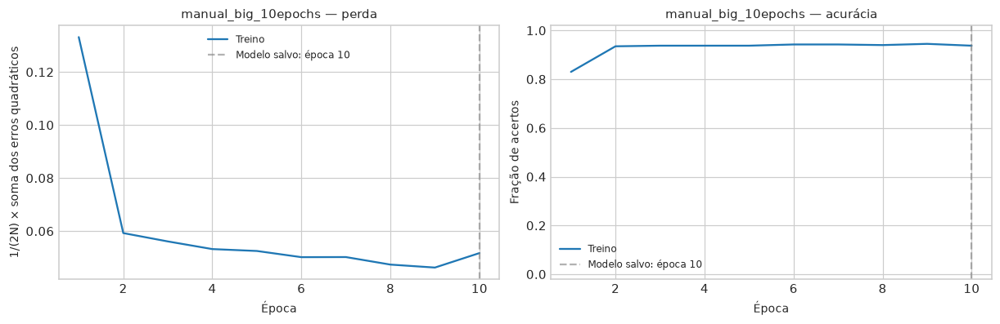

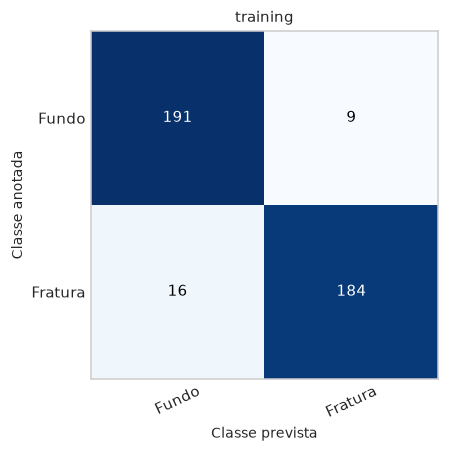

Classificação: 512/446,489 centros
Classificação: 89,600/446,489 centros
Classificação: 178,688/446,489 centros
Classificação: 267,776/446,489 centros
Classificação: 356,864/446,489 centros
Classificação: 445,952/446,489 centros
Classificação: 446,489/446,489 centros


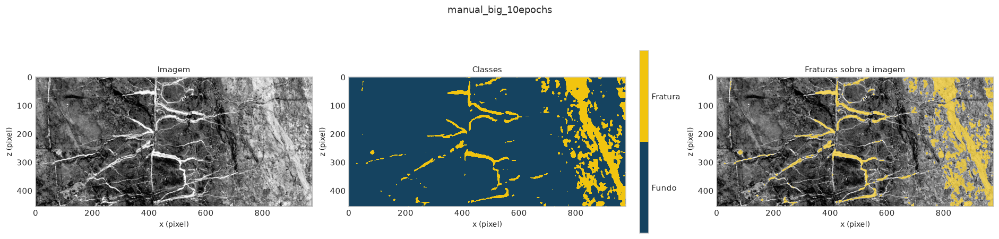

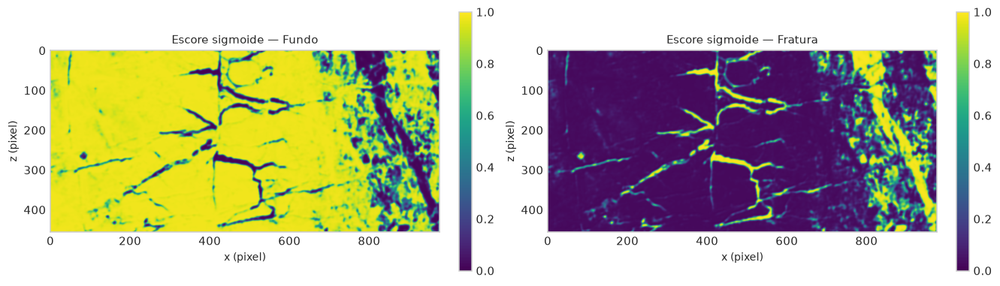

,subset,samples,loss,accuracy,precision_macro,recall_macro,f1_macro,task,experiment,parameters,epochs_run,selected_epoch,train_seconds,inference_seconds,inference_stride
0,training,400,0.0517075,0.9375,0.938037,0.9375,0.937481,binary,manual_big_10epochs,2570,10,10,0.375149,2.33865,1


,subset,label,class,support,precision,recall,f1
0,training,0,Fundo,200,0.922705,0.955,0.938575
1,training,1,Fratura,200,0.953368,0.92,0.936387


,experiment,label,class,centers,fraction,inference_stride
0,manual_big_10epochs,0,Fundo,390951,0.875612,1
1,manual_big_10epochs,1,Fratura,55538,0.124388,1


In [9]:
binary_big = run_binary("manual_big_10epochs", annotations=manual_sets["big"])

#### 5.2.1. Interpretação — picking de fraturas grandes

Nos 400 pontos desta seleção, a perda cai de **0,133163 para 0,051707** e a
acurácia de época passa de 83,00% para **93,75%**. O melhor ajuste ocorre na
época 9, com perda 0,046247 e acurácia 94,50%; a oscilação final, sem dados
reservados, não comprova sobreajuste. A média móvel `rL` termina em 0,088917.

| Subconjunto | Classe | n | Precisão (%) | Recall (%) | F1 (%) |
|---|---|---:|---:|---:|---:|
| Treino | Fundo | 200 | 92,27 | 95,50 | 93,86 |
| Treino | Fratura | 200 | 95,34 | 92,00 | 93,64 |
| Treino | **Média macro** | 400 | **93,80** | **93,75** | **93,75** |

São **191 fundos e 184 fraturas corretos**, com **9 falsos positivos e 16 falsos
negativos**, totalizando 25 erros. A precisão positiva é 95,34%, o recall,
92,00%, e o F1, 93,64%. O ajuste é melhor que o obtido no picking de pequenas
fraturas, mas as avaliações usam conjuntos distintos; essa diferença não
estabelece qual modelo generaliza melhor.

O mapa contém **55.538 pixels positivos (12,44%)**. Ele recupera partes das
estruturas mais espessas do centro, mas deixa de acompanhar diversos traços
finos à esquerda e interrompe estruturas evidentes. A textura clara à direita
recebe respostas extensas: **31,22%** dos pixels dessa faixa são positivos,
contra somente 1,56% na esquerda, `x<320`.

O mapa de escores confirma a resposta seletiva no centro e sua ativação
inadequada em parte da direita. Apenas **1,69%** dos pixels têm margem inferior
a 0,1, mostrando que a rede pode separar fortemente os escores mesmo em regiões
visualmente questionáveis. Considero o mapa insuficiente para representar toda
a rede de fraturas da imagem, apesar do bom ajuste aos exemplos grandes.
O custo foi **0,375 s de treino e 2,339 s de inferência**, com 2.570 parâmetros
e 200 atualizações. Esse orçamento em atualizações é metade do usado no
experimento combinado de 800 pontos, embora ambos tenham 10 épocas.

### 5.3. Questão 1 — Treinamento com a seleção de fraturas pequenas

Este experimento utiliza os 200 pontos de fratura e os 200 de fundo de
`annotations_small.csv`. A comparação com a seleção de fraturas grandes mantém
a arquitetura, as épocas e os hiperparâmetros, alterando somente as amostras.


manual_small_10epochs: 400 treino / 0 validação
Época   1/10 | loss=0.262877 | acurácia=0.500
Época  10/10 | loss=0.096949 | acurácia=0.870


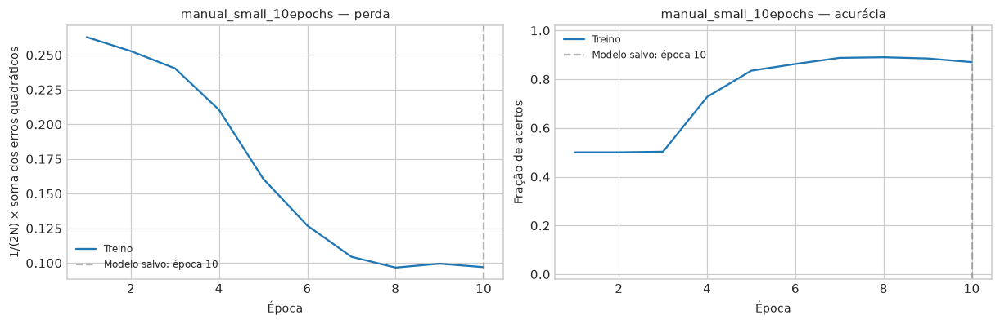

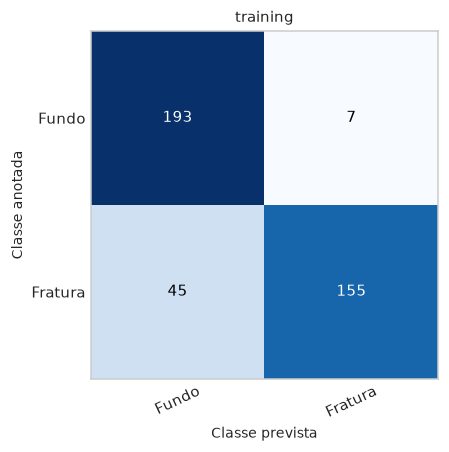

Classificação: 512/446,489 centros
Classificação: 89,600/446,489 centros
Classificação: 178,688/446,489 centros
Classificação: 267,776/446,489 centros
Classificação: 356,864/446,489 centros
Classificação: 445,952/446,489 centros
Classificação: 446,489/446,489 centros


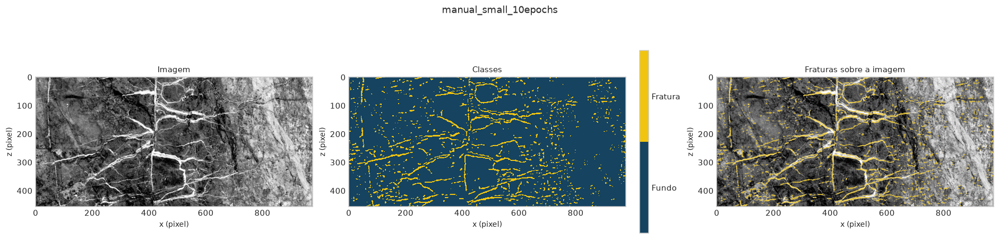

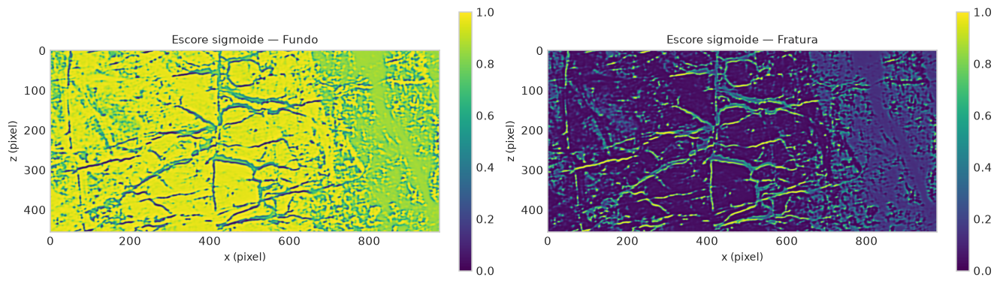

,subset,samples,loss,accuracy,precision_macro,recall_macro,f1_macro,task,experiment,parameters,epochs_run,selected_epoch,train_seconds,inference_seconds,inference_stride
0,training,400,0.0969489,0.87,0.883857,0.87,0.868816,binary,manual_small_10epochs,2570,10,10,0.376632,2.28659,1


,subset,label,class,support,precision,recall,f1
0,training,0,Fundo,200,0.810924,0.965,0.881279
1,training,1,Fratura,200,0.95679,0.775,0.856354


,experiment,label,class,centers,fraction,inference_stride
0,manual_small_10epochs,0,Fundo,408303,0.914475,1
1,manual_small_10epochs,1,Fratura,38186,0.0855251,1


In [10]:
binary_small = run_binary("manual_small_10epochs", annotations=manual_sets["small"])

#### 5.3.1. Interpretação — picking de fraturas pequenas

A perda diminui de **0,262877 para 0,096949**, e a acurácia passa de 50,00%
para **87,00%**. A menor perda ocorre na época 8, com 0,096658 e acurácia
89,00%; as últimas épocas oscilam levemente. O `rL` final, 0,163737, ainda
incorpora minibatches anteriores, não sendo equivalente à perda dos pesos finais.

| Subconjunto | Classe | n | Precisão (%) | Recall (%) | F1 (%) |
|---|---|---:|---:|---:|---:|
| Treino | Fundo | 200 | 81,09 | 96,50 | 88,13 |
| Treino | Fratura | 200 | 95,68 | 77,50 | 85,64 |
| Treino | **Média macro** | 400 | **88,39** | **87,00** | **86,88** |

A matriz apresenta **193 fundos e 155 fraturas corretos**, com **7 falsos
positivos e 45 falsos negativos**: 52 erros. A precisão positiva é 95,68%,
ligeiramente maior que no picking de grandes, mas o recall cai de 92,00% para
**77,50%**. Portanto, 22,50% das pequenas fraturas anotadas são omitidas.
O F1 positivo de 85,64% e o macro de 86,88% mostram a limitação que a precisão
isolada esconderia.

O mapa marca **38.186 pixels (8,55%)**. Em comparação com `big`, acompanha mais
ramificações finas na esquerda e no centro e reduz as manchas da direita:
essa faixa passa de 31,22% para **4,93%** de pixels positivos. Persistem pontos
isolados e interrupções, e algumas estruturas espessas são apenas parcialmente
recuperadas. O modelo não detecta exclusivamente pequenas fraturas: padrões
locais semelhantes aparecem em estruturas de diferentes larguras.

Na minha avaliação, a geometria é mais compatível com uma rede de traços finos
que no experimento anterior, mas ainda não recupera satisfatoriamente toda
a continuidade visível. A margem inferior a 0,1 ocorre em **2,74%** da imagem.
Os tempos foram **0,377 s de treino e 2,287 s de inferência**, com os mesmos
2.570 parâmetros e 200 atualizações. As duas seleções também contêm fundos
diferentes; o efeito do picking não pode ser atribuído apenas à espessura dos
exemplos positivos. O bom desempenho nos pontos de uma seleção não garante
que o restante da imagem seja classificado com o mesmo padrão de erro.

### 5.4. Questão 2 — Alteração da arquitetura

Optei por duplicar os canais de `(6, 12)` para `(12, 24)`, mantendo os demais
hiperparâmetros e o conjunto binário completo de 800 registros. A quantidade de
parâmetros e as métricas são registradas no resumo do próprio bloco binário.


wider_10epochs: 800 treino / 0 validação
Época   1/10 | loss=0.245788 | acurácia=0.500
Época  10/10 | loss=0.075845 | acurácia=0.904


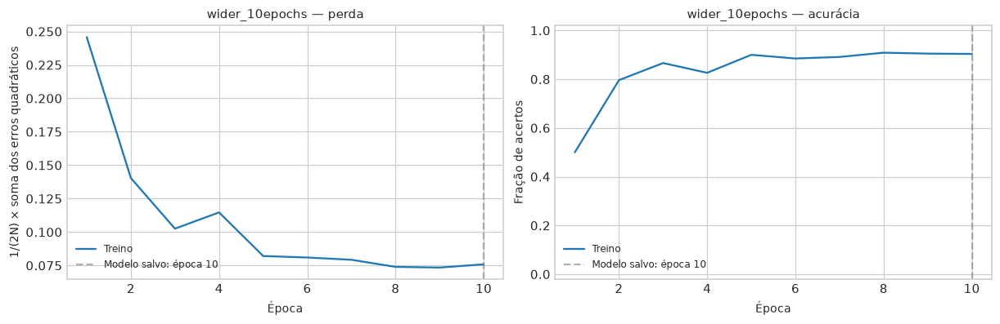

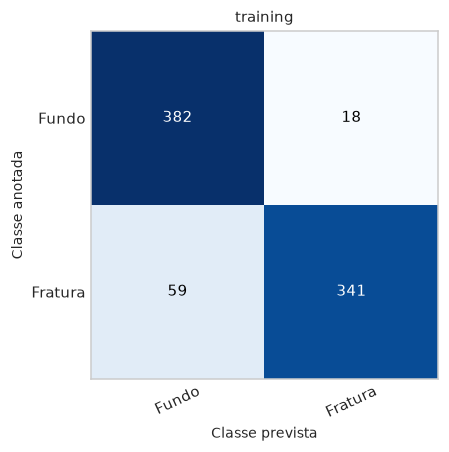

Classificação: 512/446,489 centros
Classificação: 89,600/446,489 centros
Classificação: 178,688/446,489 centros
Classificação: 267,776/446,489 centros
Classificação: 356,864/446,489 centros
Classificação: 445,952/446,489 centros
Classificação: 446,489/446,489 centros


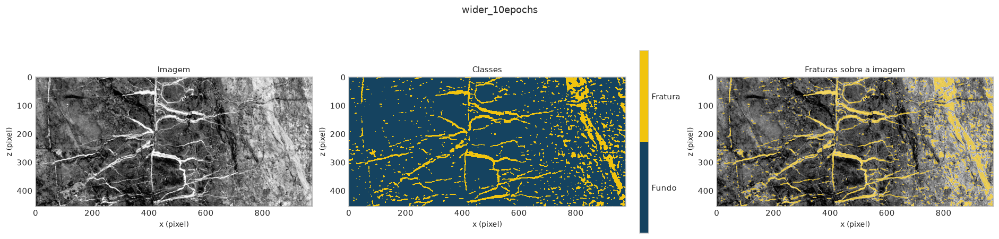

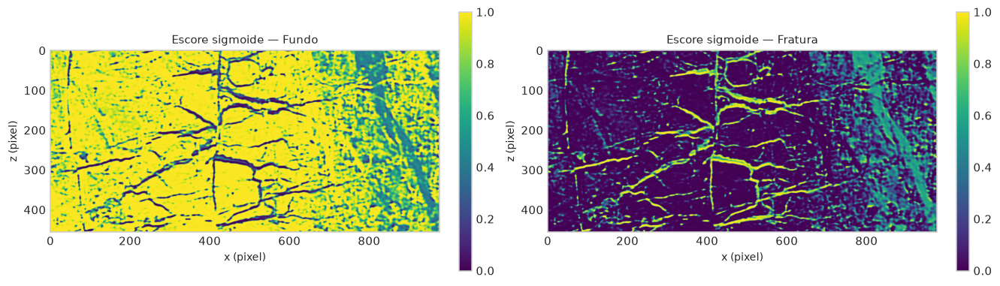

,subset,samples,loss,accuracy,precision_macro,recall_macro,f1_macro,task,experiment,parameters,epochs_run,selected_epoch,train_seconds,inference_seconds,inference_stride
0,training,800,0.0758453,0.90375,0.908037,0.90375,0.903497,binary,wider_10epochs,8738,10,10,0.744594,2.42874,1


,subset,label,class,support,precision,recall,f1
0,training,0,Fundo,400,0.866213,0.955,0.908442
1,training,1,Fratura,400,0.949861,0.8525,0.898551


,experiment,label,class,centers,fraction,inference_stride
0,wider_10epochs,0,Fundo,383547,0.859029,1
1,wider_10epochs,1,Fratura,62942,0.140971,1


In [11]:
binary_wider = run_binary("wider_10epochs", config=replace(binary_config, channels=(12, 24)))

#### 5.4.1. Interpretação — aumento da capacidade no problema binário

Duplicar os canais aumenta os parâmetros de **2.570 para 8.738**, um fator
de **3,40**, pois a segunda convolução amplia simultaneamente entradas e saídas.
A perda cai de 0,245788 na época 1 para **0,075845 na época 10**. A acurácia
final, **90,375%**, representa somente **um acerto adicional** em 800 pontos
em relação aos 90,25% da base. O F1 macro passa de 90,23% para 90,35%.

| Subconjunto | Classe | n | Precisão (%) | Recall (%) | F1 (%) |
|---|---|---:|---:|---:|---:|
| Treino | Fundo | 400 | 86,62 | 95,50 | 90,84 |
| Treino | Fratura | 400 | 94,99 | 85,25 | 89,86 |
| Treino | **Média macro** | 800 | **90,80** | **90,38** | **90,35** |

A matriz muda de `[[379, 21], [57, 343]]` para **`[[382, 18], [59, 341]]`**,
na ordem fundo/fratura. São três falsos positivos a menos, mas dois falsos
negativos adicionais. A precisão positiva aumenta de 94,23% para 94,99%,
enquanto o recall cai de 85,75% para 85,25%. A perda final fica acima da base,
mostrando que a pequena melhora de acurácia não implica menor erro quadrático.
A menor perda da rede ampliada, 0,073438, ocorre na época 9, antes do modelo final.

A área positiva diminui de 15,99% para **14,10%**, ou **62.942 pixels**.
As estruturas centrais continuam reconhecíveis, mas permanecem interrupções
e respostas dispersas na direita. A fração positiva dessa região cai de 26,05%
para 22,07%, ainda com extensa ativação em áreas texturais. A margem inferior
a 0,1 ocorre em **3,71%** dos pixels, próxima dos 3,78% da base.

Considero o ganho insuficiente para preferir a arquitetura ampliada neste
orçamento. Isso não demonstra inferioridade geral: os pesos iniciais têm
dimensões diferentes, e passo e orçamento não foram ajustados à nova rede.
O treino levou **0,745 s** e a inferência, **2,429 s**. O treino medido ficou
abaixo do primeiro experimento base, mas uma medição isolada, sem aquecimento
padronizado, não demonstra que a rede maior seja computacionalmente mais barata.

### 5.5. Questão 3 — Aumento para 100 épocas

Somente o número de épocas muda em relação à configuração base. A inicialização,
a ordem dos minibatches, o conjunto de 800 registros e o passo permanecem iguais.
As primeiras 10 épocas são verificadas numericamente. Com lotes de 20, o treinamento
de 100 épocas realiza 4.000 atualizações.


reference_100epochs: 800 treino / 0 validação
Época   1/100 | loss=0.163046 | acurácia=0.761
Época  10/100 | loss=0.074061 | acurácia=0.902
Época  20/100 | loss=0.072738 | acurácia=0.912
Época  30/100 | loss=0.047600 | acurácia=0.939
Época  40/100 | loss=0.031871 | acurácia=0.967
Época  50/100 | loss=0.030517 | acurácia=0.967
Época  60/100 | loss=0.022070 | acurácia=0.979
Época  70/100 | loss=0.021560 | acurácia=0.976
Época  80/100 | loss=0.018341 | acurácia=0.981
Época  90/100 | loss=0.018855 | acurácia=0.977
Época 100/100 | loss=0.014679 | acurácia=0.985


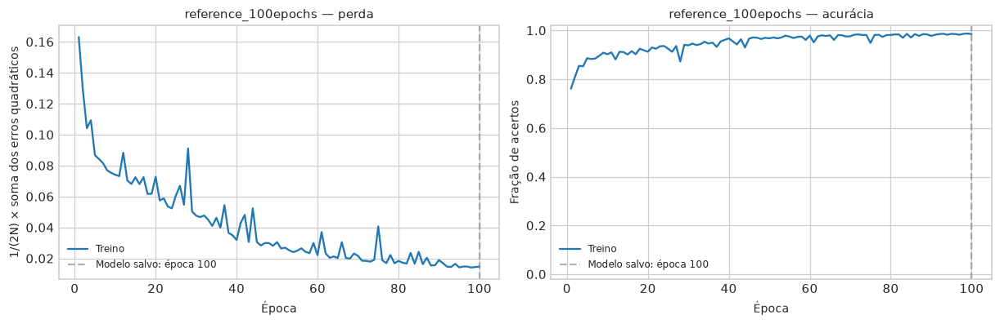

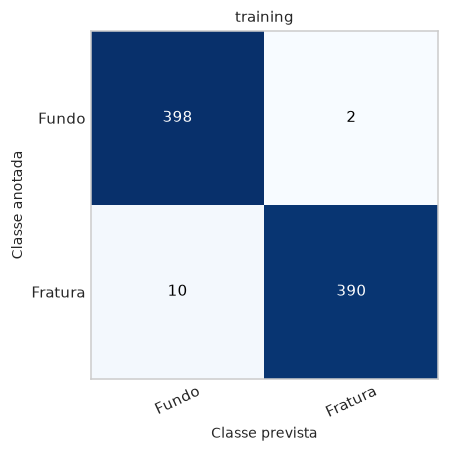

Classificação: 512/446,489 centros
Classificação: 89,600/446,489 centros
Classificação: 178,688/446,489 centros
Classificação: 267,776/446,489 centros
Classificação: 356,864/446,489 centros
Classificação: 445,952/446,489 centros
Classificação: 446,489/446,489 centros


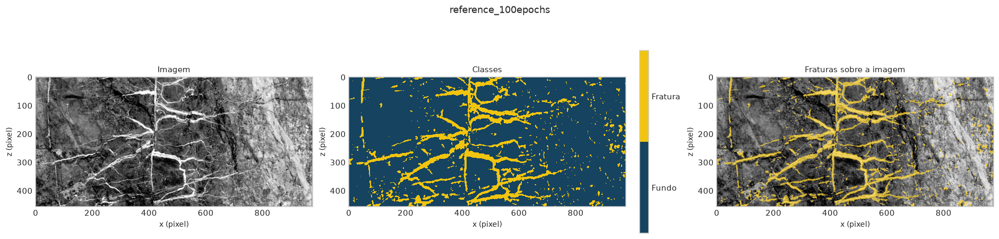

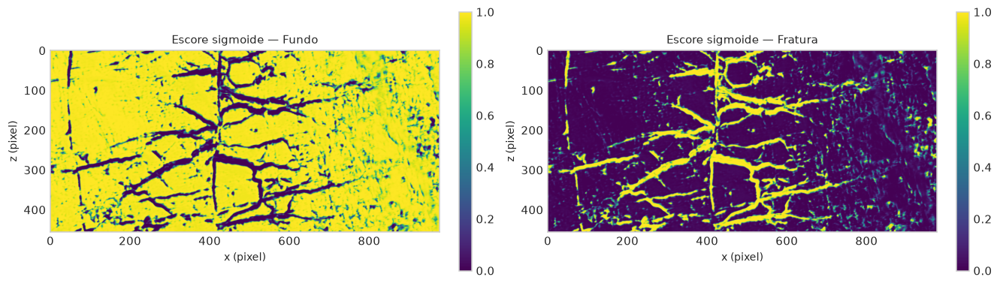

,subset,samples,loss,accuracy,precision_macro,recall_macro,f1_macro,task,experiment,parameters,epochs_run,selected_epoch,train_seconds,inference_seconds,inference_stride
0,training,800,0.0146787,0.985,0.985194,0.985,0.984998,binary,reference_100epochs,2570,100,100,6.98198,2.31113,1


,subset,label,class,support,precision,recall,f1
0,training,0,Fundo,400,0.97549,0.995,0.985149
1,training,1,Fratura,400,0.994898,0.975,0.984848


,experiment,label,class,centers,fraction,inference_stride
0,reference_100epochs,0,Fundo,383198,0.858247,1
1,reference_100epochs,1,Fratura,63291,0.141753,1


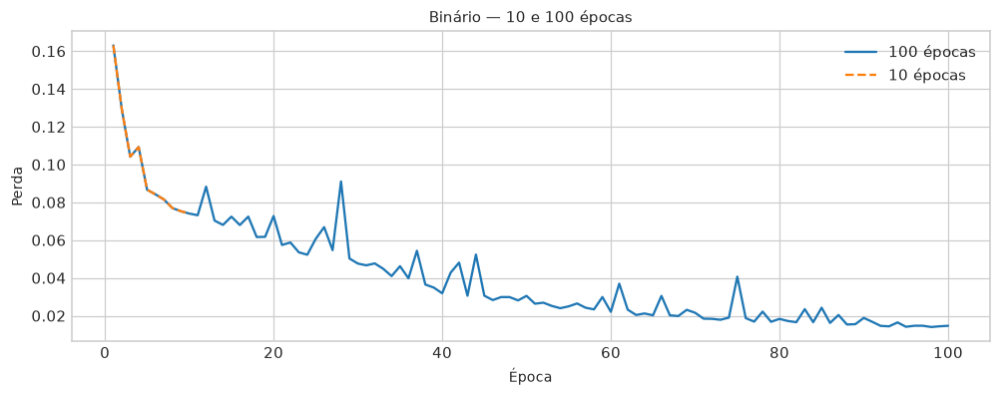

In [12]:
binary_long = run_binary("reference_100epochs", config=replace(binary_config, epochs=LONG_EPOCHS))
shared = min(len(binary_reference.history), len(binary_long.history))
np.testing.assert_allclose(binary_reference.history.train_loss.iloc[:shared],
                           binary_long.history.train_loss.iloc[:shared], rtol=1e-5, atol=1e-6)
fig, ax = plt.subplots(figsize=(9, 3.5), constrained_layout=True)
ax.plot(binary_long.history.epoch, binary_long.history.train_loss, label="100 épocas")
ax.plot(binary_reference.history.epoch, binary_reference.history.train_loss, "--", label="10 épocas")
ax.set(title="Binário — 10 e 100 épocas", xlabel="Época", ylabel="Perda")
ax.legend()
fig.savefig(binary_dir / "comparison_10_vs_100epochs.png", dpi=160)
plt.show()

#### 5.5.1. Interpretação — 100 épocas no problema binário

A perda passa de **0,074061 na época 10 para 0,014679 na época 100**, redução
de **80,18%**. A acurácia aumenta de 90,25% para **98,50%**, e o F1 macro de
90,23% para **98,50%**. A coincidência numérica das primeiras 10 épocas confirma
o mesmo início do treinamento. O orçamento cresce de 400 para **4.000 atualizações**.

| Subconjunto | Classe | n | Precisão (%) | Recall (%) | F1 (%) |
|---|---|---:|---:|---:|---:|
| Treino | Fundo | 400 | 97,55 | 99,50 | 98,51 |
| Treino | Fratura | 400 | 99,49 | 97,50 | 98,48 |
| Treino | **Média macro** | 800 | **98,52** | **98,50** | **98,50** |

A matriz final é **`[[398, 2], [10, 390]]`**. Os erros caem de 78 para 12:
os falsos positivos diminuem de 21 para 2, e os falsos negativos de 57 para 10.
A precisão positiva chega a 99,49%, o recall a 97,50% e o F1 a 98,48%.
Há 40 aumentos de perda entre épocas consecutivas, apesar da tendência global
de queda, comportamento compatível com SGD em minibatches e passo constante.
A menor perda de treino ocorre na época 98, com 0,014033, próxima do valor final.

O mapa apresenta **63.291 pixels positivos (14,18%)**. O ganho visual não é
simplesmente reduzir área: a resposta se concentra nos traços centrais e
esquerdos, enquanto a ativação da textura direita diminui. Nessa faixa, os
positivos passam de 26,05% para **5,96%**; no centro, de 14,98% para 22,81%.
Na minha avaliação, o resultado parece mais coerente com as estruturas visíveis
que o da base de 10 épocas. Ainda há espessamento, possíveis conexões entre
estruturas próximas e interrupção de alguns segmentos finos.

A margem inferior a 0,1 cai de 3,78% para **1,24%**, indicando maior separação
das saídas, sem garantir calibração ou correção. O custo foi **6,982 s de
treino e 2,311 s de inferência**, mantendo 2.570 parâmetros. O orçamento melhora
o ajuste sem alterar a complexidade do modelo aplicado à imagem. Como todos
os 800 pontos foram usados no treino, essa melhoria ainda não demonstra
generalização; a avaliação reservada deve ser examinada separadamente.

### 5.6. Questão 3 — Treinamento com validação interna

O conjunto binário é dividido por centros únicos e classe. Este experimento executa
100 épocas sem regularização ou parada antecipada; a validação é usada apenas
para monitoramento. As métricas de treino e validação são apresentadas separadamente.


validation_100epochs: 640 treino / 160 validação
Época   1/100 | loss=0.201955 | acurácia=0.695 | val_loss=0.220219
Época  10/100 | loss=0.071362 | acurácia=0.903 | val_loss=0.101753
Época  20/100 | loss=0.070214 | acurácia=0.900 | val_loss=0.101785
Época  30/100 | loss=0.050397 | acurácia=0.941 | val_loss=0.088564
Época  40/100 | loss=0.039034 | acurácia=0.953 | val_loss=0.071628
Época  50/100 | loss=0.030395 | acurácia=0.966 | val_loss=0.066635
Época  60/100 | loss=0.024011 | acurácia=0.977 | val_loss=0.058862
Época  70/100 | loss=0.023625 | acurácia=0.977 | val_loss=0.060120
Época  80/100 | loss=0.018162 | acurácia=0.983 | val_loss=0.050039
Época  90/100 | loss=0.017318 | acurácia=0.986 | val_loss=0.049717
Época 100/100 | loss=0.012247 | acurácia=0.989 | val_loss=0.043100


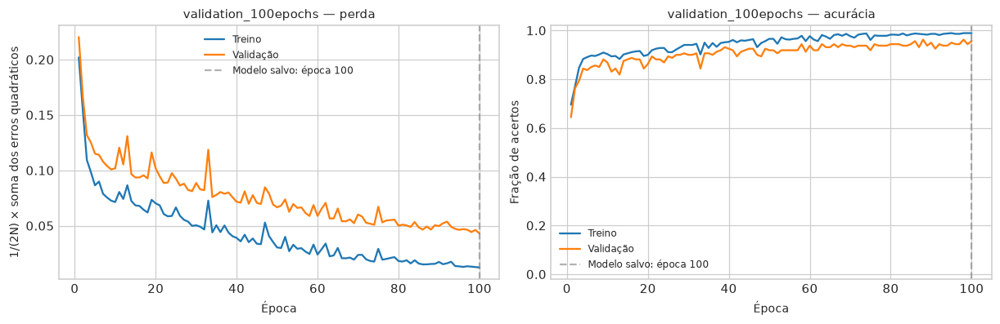

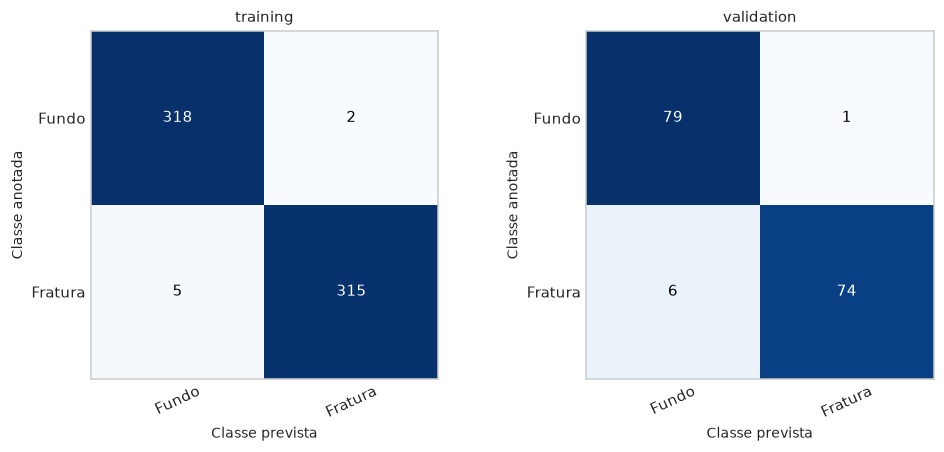

Classificação: 512/446,489 centros
Classificação: 89,600/446,489 centros
Classificação: 178,688/446,489 centros
Classificação: 267,776/446,489 centros
Classificação: 356,864/446,489 centros
Classificação: 445,952/446,489 centros
Classificação: 446,489/446,489 centros


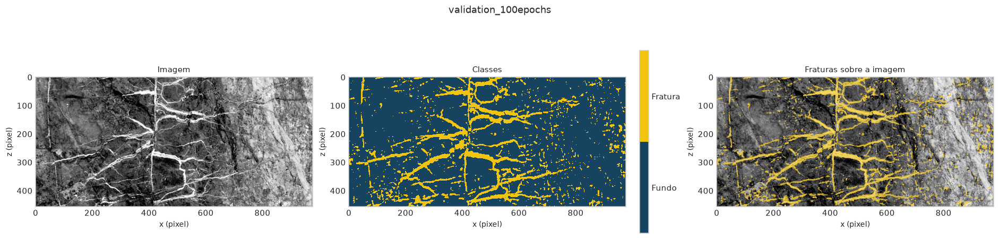

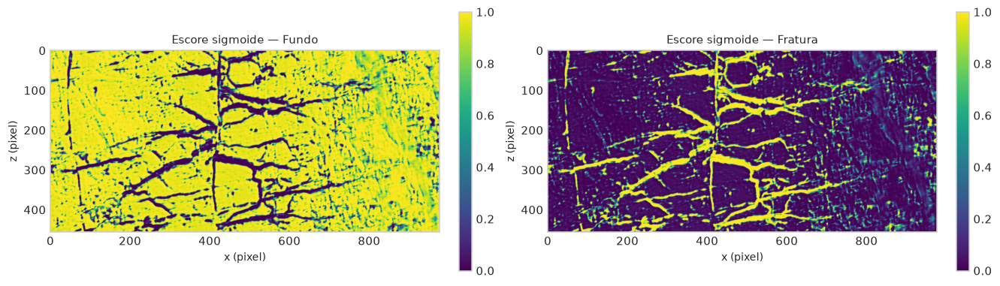

,subset,samples,loss,accuracy,precision_macro,recall_macro,f1_macro,task,experiment,parameters,epochs_run,selected_epoch,train_seconds,inference_seconds,inference_stride
0,training,640,0.0122466,0.989062,0.989105,0.989062,0.989062,binary,validation_100epochs,2570,100,100,5.82107,2.42732,1
1,validation,160,0.0431002,0.95625,0.958039,0.95625,0.956207,binary,validation_100epochs,2570,100,100,5.82107,2.42732,1


,subset,label,class,support,precision,recall,f1
0,training,0,Fundo,320,0.98452,0.99375,0.989114
1,training,1,Fratura,320,0.993691,0.984375,0.989011
2,validation,0,Fundo,80,0.929412,0.9875,0.957576
3,validation,1,Fratura,80,0.986667,0.925,0.954839


,experiment,label,class,centers,fraction,inference_stride
0,validation_100epochs,0,Fundo,378394,0.847488,1
1,validation_100epochs,1,Fratura,68095,0.152512,1


In [13]:
binary_validation = run_binary("validation_100epochs",
                               config=replace(binary_config, epochs=LONG_EPOCHS), split=True)

#### 5.6.1. Interpretação — validação binária sem regularização

O treino utiliza **640 pontos**, 320 por classe; a validação contém **160**, 80
por classe. As perdas finais são **0,012247 no treino e 0,043100 na validação**.
As acurácias de **98,906% e 95,625%** diferem em 3,281 pontos percentuais,
evidenciando ajuste mais favorável aos pontos utilizados na otimização.

| Subconjunto | Classe | n | Precisão (%) | Recall (%) | F1 (%) |
|---|---|---:|---:|---:|---:|
| Treino | Fundo | 320 | 98,45 | 99,38 | 98,91 |
| Treino | Fratura | 320 | 99,37 | 98,44 | 98,90 |
| Treino | **Média macro** | 640 | **98,91** | **98,91** | **98,91** |
| Validação | Fundo | 80 | 92,94 | 98,75 | 95,76 |
| Validação | Fratura | 80 | 98,67 | 92,50 | 95,48 |
| Validação | **Média macro** | 160 | **95,80** | **95,62** | **95,62** |

A matriz de treino é `[[318, 2], [5, 315]]`; a reservada é
**`[[79, 1], [6, 74]]`**. Os sete erros de validação incluem um falso positivo
e seis fraturas omitidas. A precisão positiva é **98,67%**, o recall, **92,50%**,
e o F1, **95,48%**. Os sete erros de treino têm proporção menor, porque o
subconjunto possui quatro vezes mais exemplos.

As curvas de treino e validação diminuem globalmente, apesar das oscilações.
A menor perda de validação ocorre na própria época 100. Portanto, não há
deterioração temporal sustentada que justifique afirmar que as 100 épocas
causaram sobreajuste severo. A lacuna treino/validação não demonstra, sozinha,
que interromper antes seria melhor.

O mapa contém **68.095 pixels positivos (15,25%)**. Ele acompanha os principais
traços, mas apresenta mais marcações dispersas e expansão de estruturas que
o modelo treinado nos 800 pontos. A faixa direita recebe 8,04% de positivos;
a margem inferior a 0,1 ocorre em 1,61% da imagem. Considero a geometria geral
plausível como apoio à identificação, com revisão dos segmentos interrompidos
e das respostas isoladas. Os tempos foram **5,821 s de treino e 2,427 s de inferência**.

A divisão por centro evita duplicação do mesmo pixel, mas não independência
dos recortes: **131 dos 160 patches de validação (81,88%) compartilham pixels
com pelo menos um patch de treino**. Todos também pertencem à mesma imagem.
Assim, os 95,625% representam validação interna possivelmente otimista, não
desempenho esperado em uma nova imagem de rocha.

### 5.7. Questão 3 — Regularização e parada antecipada

Para comparar estratégias de controle do treinamento, adotei `weight_decay=0.001`
e parada antecipada com paciência de 10 épocas e melhora mínima de `1e-5`.
A divisão e a inicialização são iguais às da subseção anterior. O treinamento
restaura os pesos da melhor época de validação e registra separadamente essa época
e o total de épocas executadas.


validation_early_stopping: 640 treino / 160 validação
Época   1/100 | loss=0.198775 | acurácia=0.702 | val_loss=0.216610
Época  10/100 | loss=0.074829 | acurácia=0.897 | val_loss=0.103769
Época  20/100 | loss=0.075499 | acurácia=0.892 | val_loss=0.105483
Época  30/100 | loss=0.061858 | acurácia=0.928 | val_loss=0.095916
Época  40/100 | loss=0.054074 | acurácia=0.939 | val_loss=0.085761
Época  50/100 | loss=0.045641 | acurácia=0.947 | val_loss=0.076556
Época  60/100 | loss=0.043627 | acurácia=0.950 | val_loss=0.073847
Época  70/100 | loss=0.051211 | acurácia=0.936 | val_loss=0.085243
Época  80/100 | loss=0.039431 | acurácia=0.950 | val_loss=0.072110
Época  90/100 | loss=0.032953 | acurácia=0.972 | val_loss=0.065702
Early stopping na época 95; melhor época: 85.


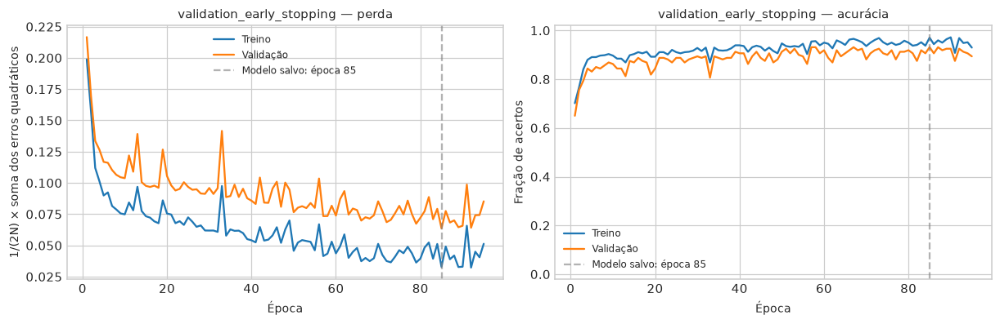

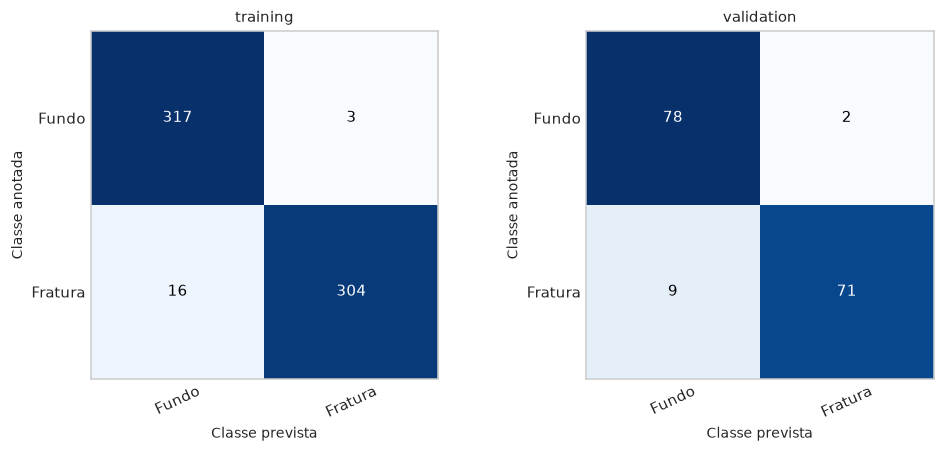

Classificação: 512/446,489 centros
Classificação: 89,600/446,489 centros
Classificação: 178,688/446,489 centros
Classificação: 267,776/446,489 centros
Classificação: 356,864/446,489 centros
Classificação: 445,952/446,489 centros
Classificação: 446,489/446,489 centros


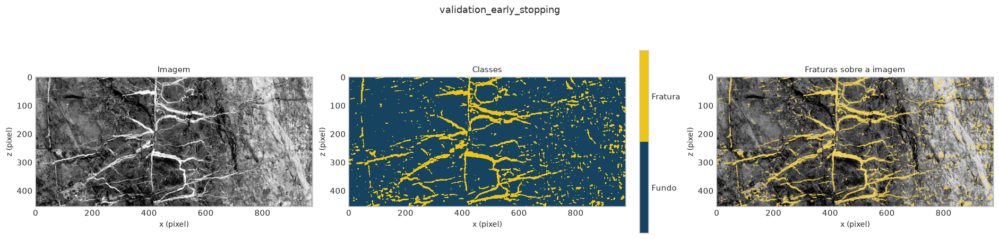

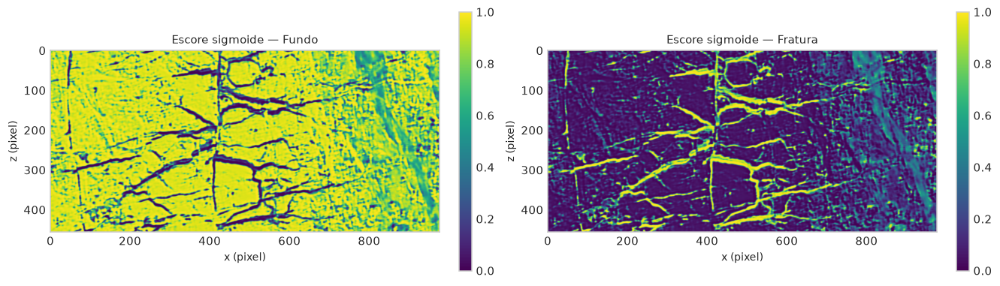

,subset,samples,loss,accuracy,precision_macro,recall_macro,f1_macro,task,experiment,parameters,epochs_run,selected_epoch,train_seconds,inference_seconds,inference_stride
0,training,640,0.0328501,0.970313,0.97109,0.970312,0.9703,binary,validation_early_stopping,2570,95,85,5.54557,2.27132,1
1,validation,160,0.0636195,0.93125,0.934577,0.93125,0.931118,binary,validation_early_stopping,2570,95,85,5.54557,2.27132,1


,subset,label,class,support,precision,recall,f1
0,training,0,Fundo,320,0.951952,0.990625,0.970904
1,training,1,Fratura,320,0.990228,0.95,0.969697
2,validation,0,Fundo,80,0.896552,0.975,0.934132
3,validation,1,Fratura,80,0.972603,0.8875,0.928105


,experiment,label,class,centers,fraction,inference_stride
0,validation_early_stopping,0,Fundo,387519,0.867925,1
1,validation_early_stopping,1,Fratura,58970,0.132075,1


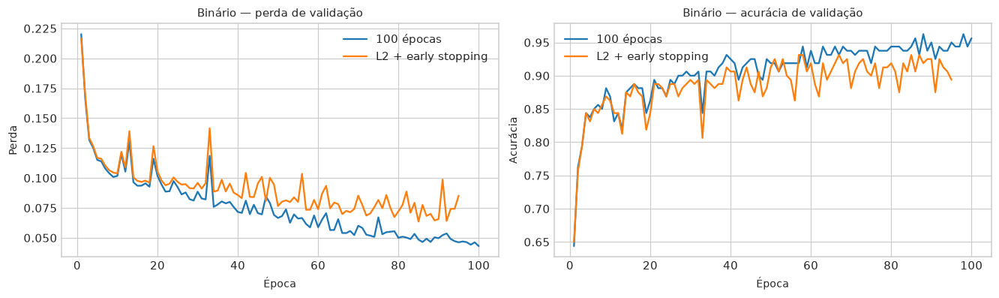

In [14]:
binary_controlled = run_binary(
    "validation_early_stopping",
    config=replace(binary_config, epochs=LONG_EPOCHS, weight_decay=1e-3,
                   patience=10, restore_best=True), split=True,
)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), constrained_layout=True)
for result, name in [(binary_validation, "100 épocas"), (binary_controlled, "L2 + early stopping")]:
    axes[0].plot(result.history.epoch, result.history.validation_loss, label=name)
    axes[1].plot(result.history.epoch, result.history.validation_accuracy, label=name)
axes[0].set(title="Binário — perda de validação", xlabel="Época", ylabel="Perda")
axes[1].set(title="Binário — acurácia de validação", xlabel="Época", ylabel="Acurácia")
for ax in axes:
    ax.legend()
fig.savefig(binary_dir / "validation_comparison.png", dpi=160)
plt.show()

#### 5.7.1. Interpretação — L2 e parada antecipada no problema binário

A execução é interrompida na época **95**, mas restaura os pesos da época **85**,
de menor perda de validação. As métricas são dos pesos restaurados, não do
último ponto das curvas. As perdas são **0,032850 no treino e 0,063619 na
validação**; as acurácias, **97,031% e 93,125%**.

| Subconjunto | Classe | n | Precisão (%) | Recall (%) | F1 (%) |
|---|---|---:|---:|---:|---:|
| Treino | Fundo | 320 | 95,20 | 99,06 | 97,09 |
| Treino | Fratura | 320 | 99,02 | 95,00 | 96,97 |
| Treino | **Média macro** | 640 | **97,11** | **97,03** | **97,03** |
| Validação | Fundo | 80 | 89,66 | 97,50 | 93,41 |
| Validação | Fratura | 80 | 97,26 | 88,75 | 92,81 |
| Validação | **Média macro** | 160 | **93,46** | **93,12** | **93,11** |

As matrizes são `[[317, 3], [16, 304]]` no treino e **`[[78, 2], [9, 71]]`**
na validação. Em relação ao modelo sem regularização, os erros reservados
aumentam de 7 para 11; a acurácia cai **2,50 pontos percentuais**, a precisão
positiva de 98,67% para 97,26% e o recall de 92,50% para **88,75%**.
A perda de validação aumenta de 0,043100 para 0,063619. Portanto, o controle
escolhido não melhora os indicadores reservados desta execução.

Na última época, 95, a perda de validação é 0,085276 e a acurácia, 89,375%.
A restauração evita esse estado pior, mas não torna o resultado superior ao
treino sem regularização. As curvas permanecem oscilatórias e a redução da
perda é mais lenta. Isso é compatível com penalização ou parada pouco adequadas
ao passo e ao orçamento, mas L2 e parada foram alteradas juntas, sem ablação
que identifique a contribuição de cada uma.

O mapa contém **58.970 pixels positivos (13,21%)**, menos que os 15,25% anteriores.
A redução não é automaticamente uma melhora: o recall cai, há perda de
continuidade e a faixa direita tem **10,03%** de positivos, acima dos 8,04%
sem regularização. A margem inferior a 0,1 cresce de 1,61% para **3,10%**.
Na minha avaliação, os indicadores e o mapa não sustentam preferência por esse controle.

Foram realizadas **3.040 atualizações**, 5% menos que as 3.200 do treino com
validação por 100 épocas. Os tempos foram **5,546 s de treino e 2,271 s de
inferência**. A economia modesta não compensou a perda de desempenho neste caso.
A dependência espacial dos patches permanece igual; regularizar os pesos
não corrige essa limitação do protocolo de avaliação.

### 5.8. Coleta dos resultados binários

O resumo reúne os experimentos binários. As interpretações anteriores discutem
as métricas de treino e validação, os mapas, os escores e o custo computacional.
As métricas de ajuste não estimam o desempenho nos demais pixels da imagem.

In [15]:
binary_summary, binary_distribution = save_section_summary(binary_results, binary_dir)
print(f"Resultados binários: {binary_dir}")

,subset,samples,loss,accuracy,precision_macro,recall_macro,f1_macro,task,experiment,parameters,epochs_run,selected_epoch,train_seconds,inference_seconds,inference_stride
0,training,800,0.0740609,0.9025,0.905787,0.9025,0.902302,binary,reference_10epochs,2570,10,10,1.32418,2.40139,1
1,training,400,0.0517075,0.9375,0.938037,0.9375,0.937481,binary,manual_big_10epochs,2570,10,10,0.375149,2.33865,1
2,training,400,0.0969489,0.87,0.883857,0.87,0.868816,binary,manual_small_10epochs,2570,10,10,0.376632,2.28659,1
3,training,800,0.0758453,0.90375,0.908037,0.90375,0.903497,binary,wider_10epochs,8738,10,10,0.744594,2.42874,1
4,training,800,0.0146787,0.985,0.985194,0.985,0.984998,binary,reference_100epochs,2570,100,100,6.98198,2.31113,1
5,training,640,0.0122466,0.989062,0.989105,0.989062,0.989062,binary,validation_100epochs,2570,100,100,5.82107,2.42732,1
6,validation,160,0.0431002,0.95625,0.958039,0.95625,0.956207,binary,validation_100epochs,2570,100,100,5.82107,2.42732,1
7,training,640,0.0328501,0.970313,0.97109,0.970312,0.9703,binary,validation_early_stopping,2570,95,85,5.54557,2.27132,1
8,validation,160,0.0636195,0.93125,0.934577,0.93125,0.931118,binary,validation_early_stopping,2570,95,85,5.54557,2.27132,1


,experiment,label,class,centers,fraction,inference_stride,task
0,reference_10epochs,0,Fundo,375093,0.840095,1,binary
1,reference_10epochs,1,Fratura,71396,0.159905,1,binary
2,manual_big_10epochs,0,Fundo,390951,0.875612,1,binary
3,manual_big_10epochs,1,Fratura,55538,0.124388,1,binary
4,manual_small_10epochs,0,Fundo,408303,0.914475,1,binary
5,manual_small_10epochs,1,Fratura,38186,0.0855251,1,binary
6,wider_10epochs,0,Fundo,383547,0.859029,1,binary
7,wider_10epochs,1,Fratura,62942,0.140971,1,binary
8,reference_100epochs,0,Fundo,383198,0.858247,1,binary
9,reference_100epochs,1,Fratura,63291,0.141753,1,binary


Resultados binários: /mnt/c/Users/Lucas Torres/Documents/Acadêmico/Doutorado/Tópicos Especiais em Processamento Inteligente da Informação/exercise04/results/main/binary


## 6. Classificação multiclasse — questão 4 e experimentos complementares

Este bloco utiliza **400 pontos de fundo, 200 de fratura grande e 200 de fratura
pequena**. Os fundos de `big` e `small` recebem rótulo 0; as fraturas de `big`
recebem 1 e as de `small`, 2. O conjunto é derivado automaticamente na seção 3.
Não há arquivo adicional a selecionar ou picker multiclasse.

A configuração mantém a função de perda do laboratório, sem reamostragem ou pesos
adicionais por classe. A camada final passa a ter três saídas. O bloco inicializa
seus próprios modelos e pode ser executado após a preparação comum, sem executar
a seção binária. Seus resultados ficam em `results/main/multiclass/`.

,Amostras
label,
0,400
1,200
2,200


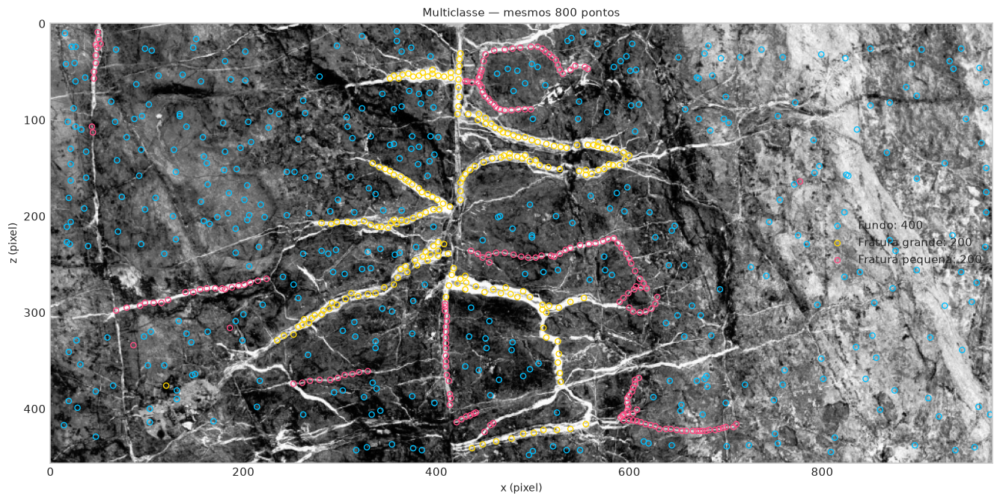

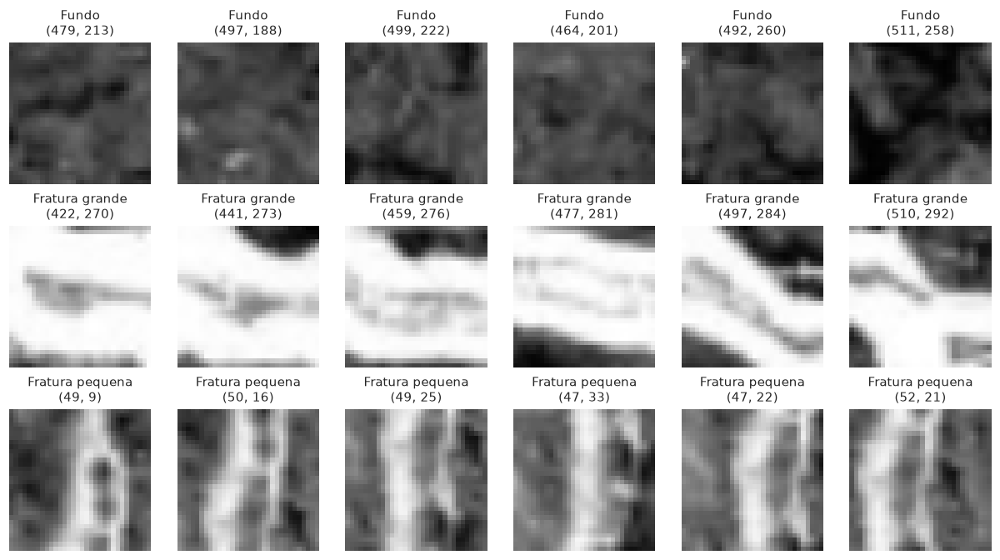

In [16]:
multiclass_dir = RUN_DIR / "multiclass"
multiclass_dir.mkdir(parents=True, exist_ok=True)
multiclass_results = {}
multiclass_annotations = combined_multiclass.copy(deep=True)
multiclass_annotations.to_csv(multiclass_dir / "dataset.csv", index=False)
multiclass_config = TrainConfig(epochs=REFERENCE_EPOCHS, batch_size=TRAIN_BATCH_SIZE,
                                learning_rate=1.0, channels=(6, 12), kernel_size=5, seed=RANDOM_SEED)


def run_multiclass(name, config=None, split=False):
    return run_experiment(
        name, multiclass_annotations, multiclass_config if config is None else config,
        classes=MULTICLASS_CLASSES, output_dir=multiclass_dir,
        registry=multiclass_results, split=split,
    )


display(multiclass_annotations.groupby("label").size().rename("Amostras").to_frame())
plot_annotations(multiclass_annotations, MULTICLASS_CLASSES, "Multiclasse — mesmos 800 pontos",
                 multiclass_dir / "annotations.png")
plot_patch_examples(multiclass_annotations, MULTICLASS_CLASSES, multiclass_dir / "patch_examples.png")

### 6.1. Configuração base multiclasse — 10 épocas

A CNN utiliza três saídas sigmoides, alvos one-hot e decisão por argmax, conservando
o erro quadrático do MATLAB. As métricas são registradas para cada classe e pela
média macro. O treinamento utiliza os 800 registros, sem divisão para validação.


reference_10epochs: 800 treino / 0 validação
Época   1/10 | loss=0.257692 | acurácia=0.544
Época  10/10 | loss=0.113905 | acurácia=0.854


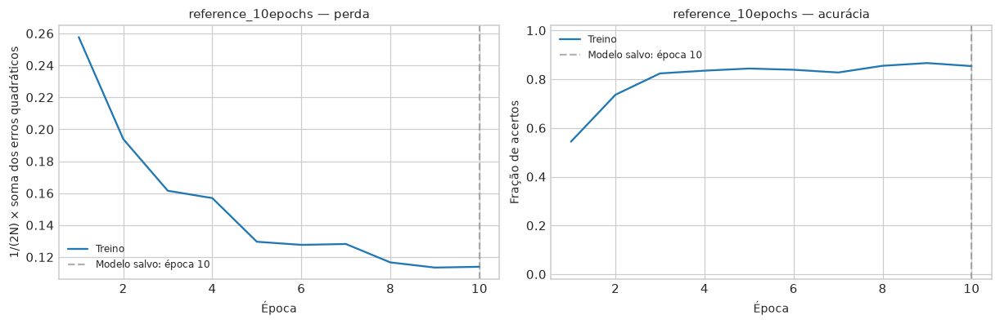

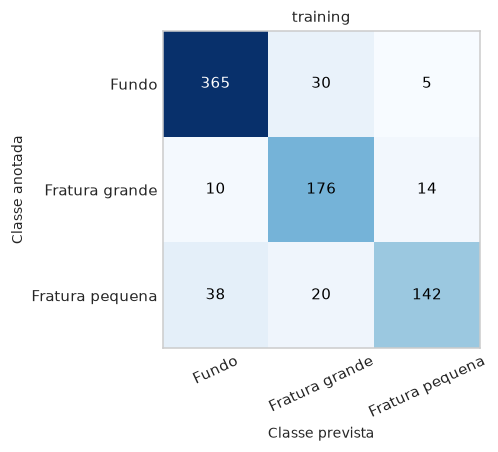

Classificação: 512/446,489 centros
Classificação: 89,600/446,489 centros
Classificação: 178,688/446,489 centros
Classificação: 267,776/446,489 centros
Classificação: 356,864/446,489 centros
Classificação: 445,952/446,489 centros
Classificação: 446,489/446,489 centros


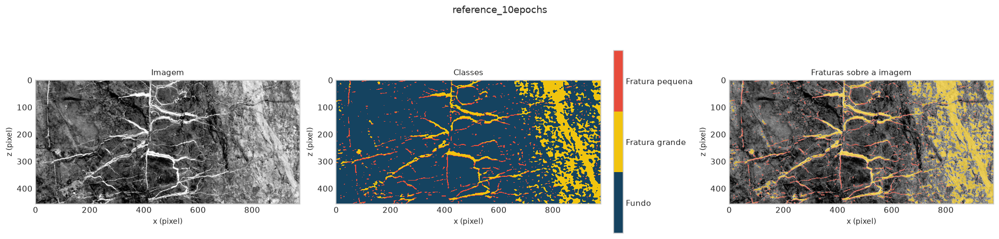

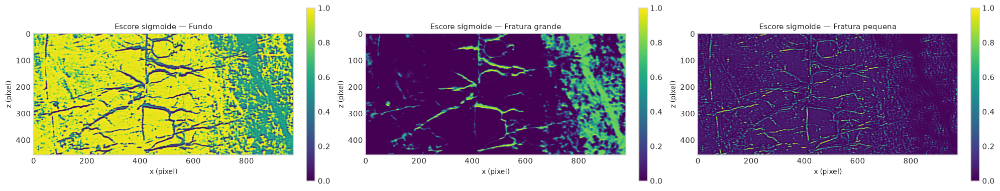

,subset,samples,loss,accuracy,precision_macro,recall_macro,f1_macro,task,experiment,parameters,epochs_run,selected_epoch,train_seconds,inference_seconds,inference_stride
0,training,800,0.113905,0.85375,0.848175,0.834167,0.836968,multiclass,reference_10epochs,2871,10,10,0.690154,2.32012,1


,subset,label,class,support,precision,recall,f1
0,training,0,Fundo,400,0.883777,0.9125,0.897909
1,training,1,Fratura grande,200,0.778761,0.88,0.826291
2,training,2,Fratura pequena,200,0.881988,0.71,0.786704


,experiment,label,class,centers,fraction,inference_stride
0,reference_10epochs,0,Fundo,360476,0.807357,1
1,reference_10epochs,1,Fratura grande,64276,0.143959,1
2,reference_10epochs,2,Fratura pequena,21737,0.0486843,1


CrackCNN(
  (features): Sequential(
    (0): MatlabConv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
    (1): Sigmoid()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): MatlabConv2d(6, 12, kernel_size=(5, 5), stride=(1, 1))
    (4): Sigmoid()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
  )
  (classifier): Linear(in_features=300, out_features=3, bias=True)
)
Parâmetros: 2871


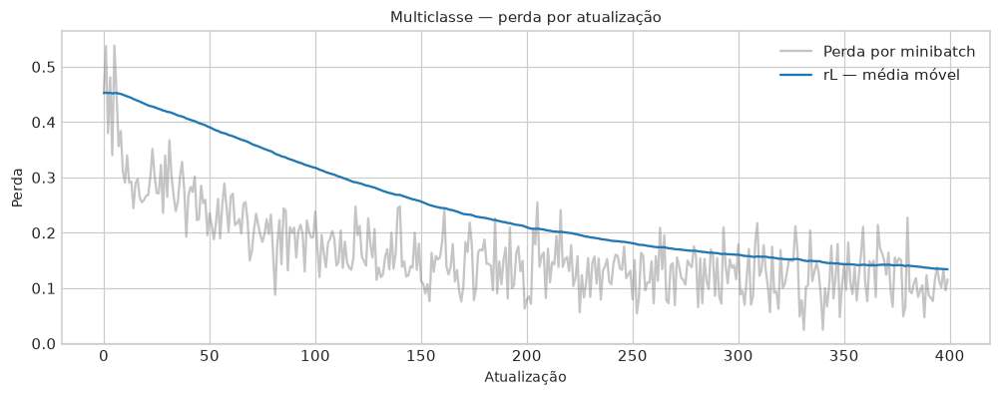

In [17]:
multiclass_reference = run_multiclass("reference_10epochs")
print(multiclass_reference.model)
print(f"Parâmetros: {sum(p.numel() for p in multiclass_reference.model.parameters())}")
fig, ax = plt.subplots(figsize=(9, 3.5), constrained_layout=True)
ax.plot(multiclass_reference.batches.loss, color="gray", alpha=0.45, label="Perda por minibatch")
ax.plot(multiclass_reference.batches.rL, label="rL — média móvel")
ax.set(title="Multiclasse — perda por atualização", xlabel="Atualização", ylabel="Perda")
ax.legend()
fig.savefig(multiclass_dir / "reference_10epochs" / "matlab_rL.png", dpi=160)
plt.show()

#### 6.1.1. Interpretação — configuração multiclasse base

O conjunto contém **400 fundos, 200 grandes fraturas e 200 pequenas**.
A perda diminui de 0,257692 na primeira época para **0,113905 na décima**.
A acurácia é **85,375%** e o F1 macro, **83,70%**. O fundo representa metade
das amostras e tem maior influência na acurácia; o recall e o F1 macro atribuem
o mesmo peso às três classes. Prever somente fundo daria 50% de acurácia:
há aprendizado, mas a recuperação das classes não é uniforme.

| Subconjunto | Classe | n | Precisão (%) | Recall (%) | F1 (%) |
|---|---|---:|---:|---:|---:|
| Treino | Fundo | 400 | 88,38 | 91,25 | 89,79 |
| Treino | Fratura grande | 200 | 77,88 | 88,00 | 82,63 |
| Treino | Fratura pequena | 200 | 88,20 | 71,00 | 78,67 |
| Treino | **Média macro** | 800 | **84,82** | **83,42** | **83,70** |

A matriz, na ordem fundo/grande/pequena, é
**`[[365, 30, 5], [10, 176, 14], [38, 20, 142]]`**. Os 117 erros incluem
**35 fundos previstos como fratura, 48 fraturas omitidas e 34 trocas de tipo**:
14 grandes previstas como pequenas e 20 pequenas como grandes. O recall das
pequenas, **71,00%**, é o principal limite, contra 88,00% nas grandes.
As respostas de fundo como grande também reduzem a precisão dessa classe a
77,88%. A menor perda ocorre na época 9, com 0,113412, mas o modelo segue
o orçamento fixo de 10 épocas. O `rL` final, 0,134008, suaviza as perdas
anteriores e não deve ser confundido com a avaliação final.

O mapa atribui **64.276 pixels (14,40%)** a grandes, **21.737 (4,87%)** a pequenas
e 80,74% ao fundo. As duas classes positivas ocupam **19,26%** da imagem.
Há uma separação inicial entre traços espessos amarelos e finos vermelhos,
mas a direita contém extensas respostas amarelas em textura: **36,99%** da
faixa recebe a classe grande. Também aparecem trocas de cor ao longo de
estruturas contínuas e interrupções de traços finos. Considero o resultado
promissor como diferenciação inicial, mas espacialmente inconsistente.

Os escores da classe grande respondem fortemente à direita, enquanto pequenas
fraturas têm menor separação. A margem entre as duas saídas mais altas é
inferior a 0,1 em **5,38%** dos pixels. A rede possui **2.871 parâmetros**,
301 a mais que a binária, com **0,690 s de treino e 2,320 s de inferência**.
O valor absoluto da perda não é diretamente comparável ao binário: agora
inclui três saídas e uma tarefa de decisão adicional.

### 6.2. Multiclasse — Alteração da arquitetura

Os canais passam de `(6, 12)` para `(12, 24)`. As três classes, os 800 registros,
as 10 épocas e os demais hiperparâmetros permanecem iguais aos da base multiclasse.


wider_10epochs: 800 treino / 0 validação
Época   1/10 | loss=0.499706 | acurácia=0.500
Época  10/10 | loss=0.108086 | acurácia=0.864


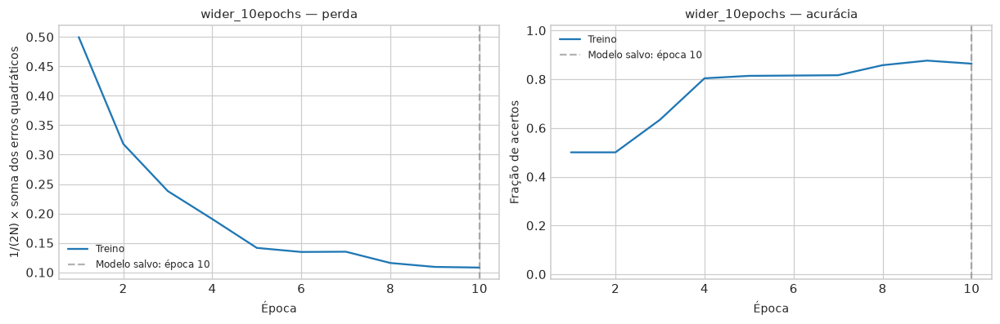

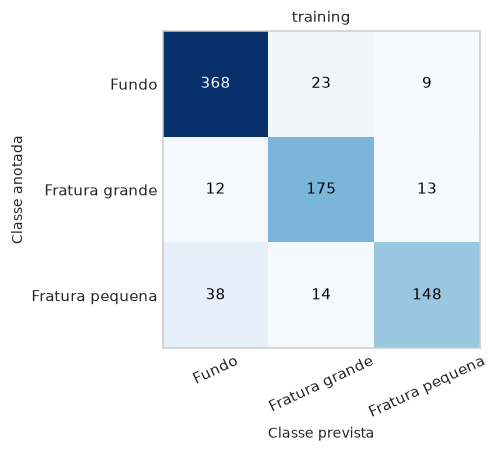

Classificação: 512/446,489 centros
Classificação: 89,600/446,489 centros
Classificação: 178,688/446,489 centros
Classificação: 267,776/446,489 centros
Classificação: 356,864/446,489 centros
Classificação: 445,952/446,489 centros
Classificação: 446,489/446,489 centros


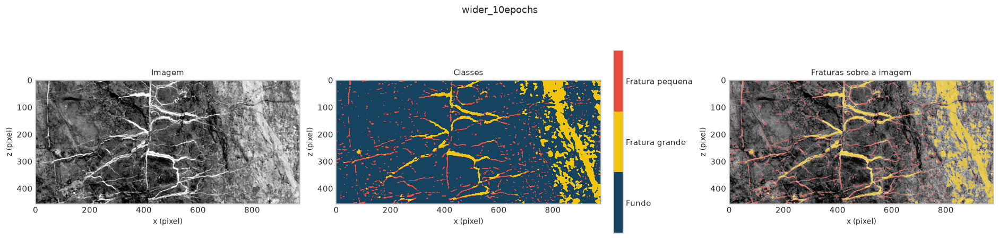

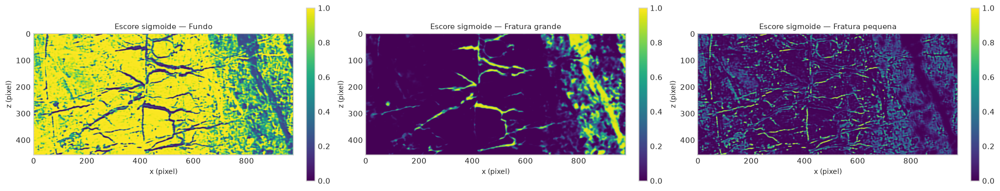

,subset,samples,loss,accuracy,precision_macro,recall_macro,f1_macro,task,experiment,parameters,epochs_run,selected_epoch,train_seconds,inference_seconds,inference_stride
0,training,800,0.108086,0.86375,0.858814,0.845,0.849757,multiclass,wider_10epochs,9339,10,10,0.758924,2.48548,1


,subset,label,class,support,precision,recall,f1
0,training,0,Fundo,400,0.880383,0.92,0.899756
1,training,1,Fratura grande,200,0.825472,0.875,0.849515
2,training,2,Fratura pequena,200,0.870588,0.74,0.8


,experiment,label,class,centers,fraction,inference_stride
0,wider_10epochs,0,Fundo,370764,0.830399,1
1,wider_10epochs,1,Fratura grande,48950,0.109633,1
2,wider_10epochs,2,Fratura pequena,26775,0.0599679,1


In [18]:
multiclass_wider = run_multiclass("wider_10epochs",
                                 config=replace(multiclass_config, channels=(12, 24)))

#### 6.2.1. Interpretação — aumento da capacidade no problema multiclasse

Os parâmetros aumentam de **2.871 para 9.339**, fator de **3,25**.
A perda final passa de 0,113905 para **0,108086**, e a acurácia de 85,375%
para **86,375%**: oito acertos adicionais em 800 pontos. O F1 macro sobe de
83,70% para **84,98%**. A perda da primeira época, 0,499706, é maior que a
da base, mas cai até a última época; a mesma semente não produz pesos iniciais
equivalentes em arquiteturas com dimensões diferentes.

| Subconjunto | Classe | n | Precisão (%) | Recall (%) | F1 (%) |
|---|---|---:|---:|---:|---:|
| Treino | Fundo | 400 | 88,04 | 92,00 | 89,98 |
| Treino | Fratura grande | 200 | 82,55 | 87,50 | 84,95 |
| Treino | Fratura pequena | 200 | 87,06 | 74,00 | 80,00 |
| Treino | **Média macro** | 800 | **85,88** | **84,50** | **84,98** |

A matriz é **`[[368, 23, 9], [12, 175, 13], [38, 14, 148]]`**, com 109 erros:
**32 falsos positivos de detecção, 50 fraturas omitidas e 27 trocas de tipo**.
Sete das oito correções líquidas em relação à base vêm da redução das trocas
grande/pequena; a detecção agregada fratura/fundo melhora somente um acerto.
O recall das pequenas sobe de 71,00% para **74,00%**, com precisão de 88,20%
para 87,06%. Nas grandes, a precisão aumenta de 77,88% para **82,55%**, mas
o recall passa de 88,00% para 87,50%. O ganho envolve um compromisso entre
recuperação e seletividade, não melhora uniforme de todas as métricas.

O mapa contém **48.950 pixels grandes (10,96%)**, **26.775 pequenos (6,00%)**
e 83,04% de fundo. A área positiva agregada cai de 19,26% para **16,96%**,
enquanto a participação das pequenas aumenta. Há mais traços finos reconhecidos
e redução parcial das manchas amarelas à direita. Entretanto, **27,61%** da
faixa direita ainda recebe a classe grande, e persistem mudanças de rótulo
ao longo de um mesmo traço e ativações texturais.

Na minha avaliação, a melhoria quantitativa e visual é moderada para o aumento
de capacidade. A margem inferior a 0,1 diminui de 5,38% para **4,41%**, mas
não elimina esses erros aparentes. Os tempos foram **0,759 s de treino e
2,485 s de inferência**. Uma única semente, com hiperparâmetros mantidos, não
permite estabelecer vantagem estatística da arquitetura maior ou antecipar
seu desempenho após ajuste específico do treinamento.

### 6.3. Multiclasse — Aumento para 100 épocas

O treinamento prolongado mantém os dados e os parâmetros da base multiclasse,
alterando somente o número de épocas. A verificação das primeiras 10 épocas
é realizada em relação à referência deste próprio bloco.


reference_100epochs: 800 treino / 0 validação
Época   1/100 | loss=0.257692 | acurácia=0.544
Época  10/100 | loss=0.113905 | acurácia=0.854
Época  20/100 | loss=0.092628 | acurácia=0.890
Época  30/100 | loss=0.077255 | acurácia=0.906
Época  40/100 | loss=0.056301 | acurácia=0.939
Época  50/100 | loss=0.053954 | acurácia=0.934
Época  60/100 | loss=0.045753 | acurácia=0.952
Época  70/100 | loss=0.043725 | acurácia=0.949
Época  80/100 | loss=0.037508 | acurácia=0.961
Época  90/100 | loss=0.035981 | acurácia=0.959
Época 100/100 | loss=0.031500 | acurácia=0.969


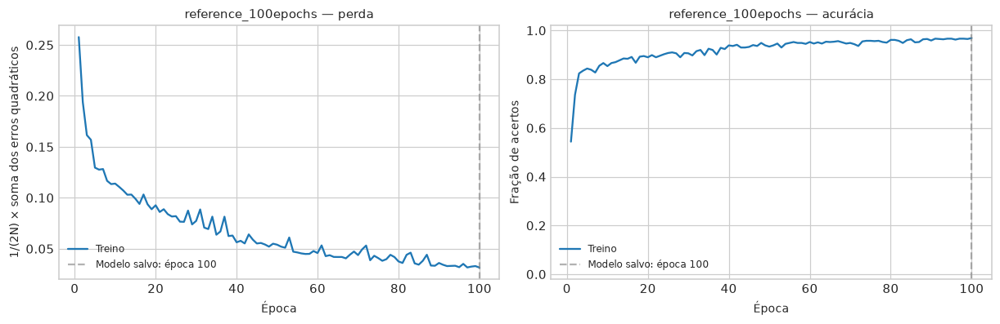

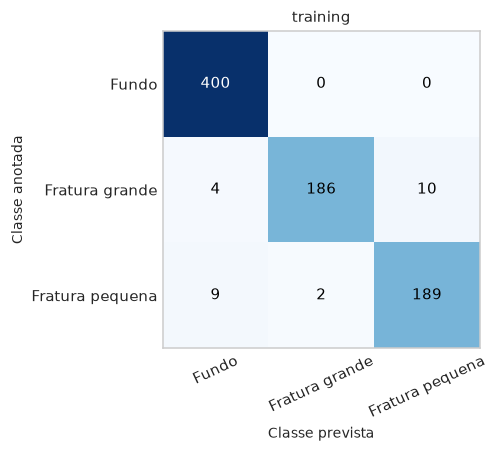

Classificação: 512/446,489 centros
Classificação: 89,600/446,489 centros
Classificação: 178,688/446,489 centros
Classificação: 267,776/446,489 centros
Classificação: 356,864/446,489 centros
Classificação: 445,952/446,489 centros
Classificação: 446,489/446,489 centros


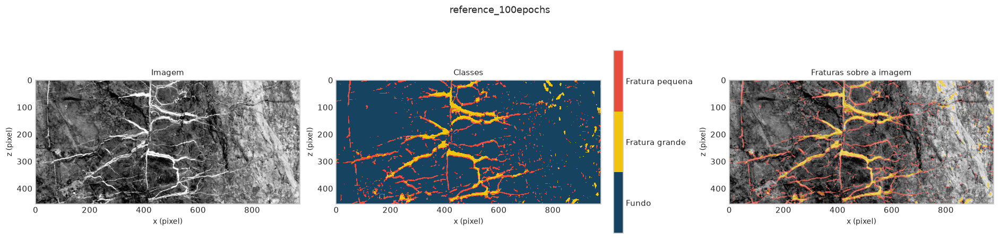

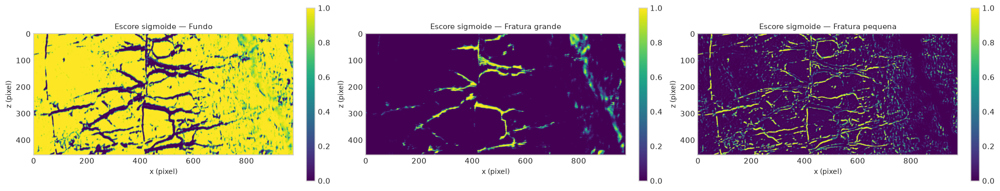

,subset,samples,loss,accuracy,precision_macro,recall_macro,f1_macro,task,experiment,parameters,epochs_run,selected_epoch,train_seconds,inference_seconds,inference_stride
0,training,800,0.0314995,0.96875,0.969211,0.958333,0.96338,multiclass,reference_100epochs,2871,100,100,7.09055,2.36263,1


,subset,label,class,support,precision,recall,f1
0,training,0,Fundo,400,0.968523,1,0.98401
1,training,1,Fratura grande,200,0.989362,0.93,0.958763
2,training,2,Fratura pequena,200,0.949749,0.945,0.947368


,experiment,label,class,centers,fraction,inference_stride
0,reference_100epochs,0,Fundo,389559,0.872494,1
1,reference_100epochs,1,Fratura grande,20024,0.0448477,1
2,reference_100epochs,2,Fratura pequena,36906,0.0826583,1


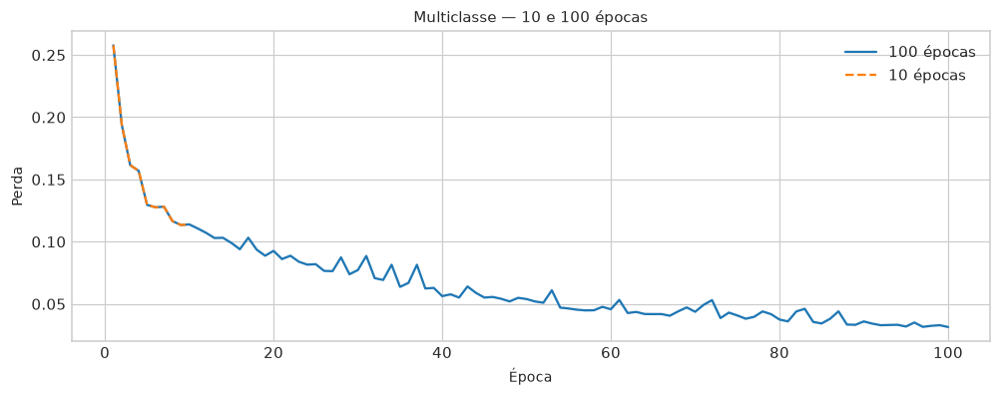

In [19]:
multiclass_long = run_multiclass("reference_100epochs",
                                config=replace(multiclass_config, epochs=LONG_EPOCHS))
shared = min(len(multiclass_reference.history), len(multiclass_long.history))
np.testing.assert_allclose(multiclass_reference.history.train_loss.iloc[:shared],
                           multiclass_long.history.train_loss.iloc[:shared], rtol=1e-5, atol=1e-6)
fig, ax = plt.subplots(figsize=(9, 3.5), constrained_layout=True)
ax.plot(multiclass_long.history.epoch, multiclass_long.history.train_loss, label="100 épocas")
ax.plot(multiclass_reference.history.epoch, multiclass_reference.history.train_loss, "--", label="10 épocas")
ax.set(title="Multiclasse — 10 e 100 épocas", xlabel="Época", ylabel="Perda")
ax.legend()
fig.savefig(multiclass_dir / "comparison_10_vs_100epochs.png", dpi=160)
plt.show()

#### 6.3.1. Interpretação — 100 épocas no problema multiclasse

A perda diminui de **0,113905 na época 10 para 0,031500 na época 100**,
redução de **72,35%**. A acurácia aumenta de 85,375% para **96,875%** e o
F1 macro de 83,70% para **96,34%**. As primeiras 10 épocas coincidem com a
referência, e o orçamento cresce para **4.000 atualizações**. Há 41 aumentos
de perda entre épocas consecutivas, mas a tendência permanece descendente
e o menor valor ocorre na época 100. O `rL` final é 0,035302, próximo da
perda de avaliação, mas ainda referente ao histórico de minibatches.

| Subconjunto | Classe | n | Precisão (%) | Recall (%) | F1 (%) |
|---|---|---:|---:|---:|---:|
| Treino | Fundo | 400 | 96,85 | 100,00 | 98,40 |
| Treino | Fratura grande | 200 | 98,94 | 93,00 | 95,88 |
| Treino | Fratura pequena | 200 | 94,97 | 94,50 | 94,74 |
| Treino | **Média macro** | 800 | **96,92** | **95,83** | **96,34** |

A matriz final é **`[[400, 0, 0], [4, 186, 10], [9, 2, 189]]`**.
Os erros caem de 117 para **25**: nenhum fundo anotado é previsto como fratura,
mas há **13 fraturas omitidas** (4 grandes e 9 pequenas) e **12 trocas de tipo**
(10 grandes como pequenas e 2 no sentido oposto). O recall das pequenas passa
de 71,00% para **94,50%**, e o das grandes chega a 93,00%. A precisão de
98,94% das grandes indica maior seletividade; a das pequenas, 94,97%, também
incorpora as grandes que recebem seu rótulo.

O mapa contém **20.024 pixels grandes (4,48%)**, **36.906 pequenos (8,27%)**
e 87,25% de fundo. A fração positiva agregada é **12,75%**. O principal ganho
visual é suprimir grandes manchas na direita: a classe grande passa de 36,99%
para **2,54%** dos pixels dessa faixa. Os traços centrais ficam mais definidos
e há maior extensão dos finos. Entretanto, estruturas espessas podem apresentar
bordas vermelhas e interior amarelo, com mudança local de classe: a classificação
por patches não impõe consistência de tipo ao longo de uma estrutura inteira.

Considero esse mapa mais plausível que os multiclasse de 10 épocas, principalmente
na separação do fundo. A maior área atribuída a pequenas fraturas não demonstra
maior quantidade física delas: são pixels previstos, não objetos contados.
A margem inferior a 0,1 cai para **2,68%**, com saídas mais separadas.
O custo foi **7,091 s de treino e 2,363 s de inferência**, com 2.871 parâmetros.
Os indicadores continuam sendo de treinamento; não representam teste independente.

### 6.4. Multiclasse — Treinamento com validação interna

A divisão é estratificada por classe e agrupa centros repetidos. O treinamento
executa 100 épocas sem parada antecipada. Nenhuma divisão ou modelo da seção
binária é reutilizado.


validation_100epochs: 640 treino / 160 validação
Época   1/100 | loss=0.268364 | acurácia=0.500 | val_loss=0.274049
Época  10/100 | loss=0.120450 | acurácia=0.839 | val_loss=0.133351
Época  20/100 | loss=0.094737 | acurácia=0.883 | val_loss=0.102129
Época  30/100 | loss=0.074642 | acurácia=0.920 | val_loss=0.092533
Época  40/100 | loss=0.058610 | acurácia=0.936 | val_loss=0.085360
Época  50/100 | loss=0.051439 | acurácia=0.944 | val_loss=0.086912
Época  60/100 | loss=0.049812 | acurácia=0.950 | val_loss=0.085448
Época  70/100 | loss=0.037867 | acurácia=0.961 | val_loss=0.081911
Época  80/100 | loss=0.034872 | acurácia=0.961 | val_loss=0.077825
Época  90/100 | loss=0.034978 | acurácia=0.961 | val_loss=0.081902
Época 100/100 | loss=0.030186 | acurácia=0.967 | val_loss=0.077523


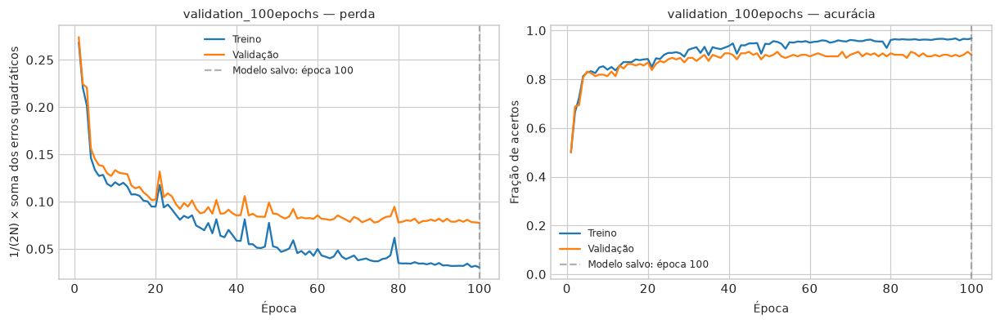

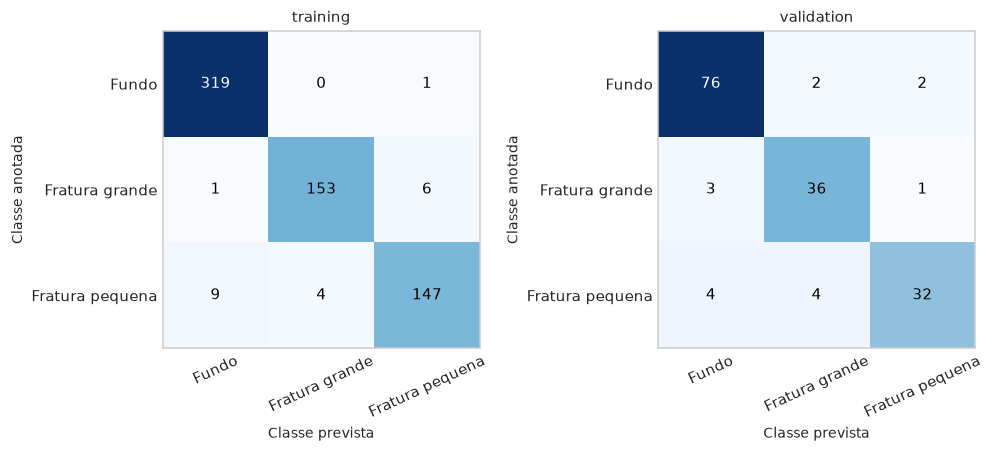

Classificação: 512/446,489 centros
Classificação: 89,600/446,489 centros
Classificação: 178,688/446,489 centros
Classificação: 267,776/446,489 centros
Classificação: 356,864/446,489 centros
Classificação: 445,952/446,489 centros
Classificação: 446,489/446,489 centros


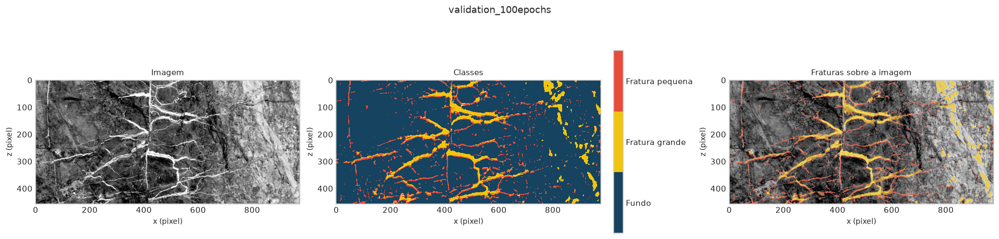

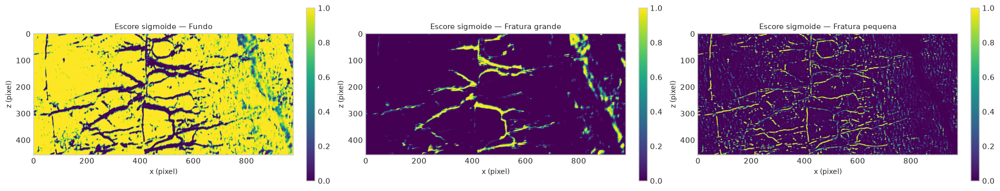

,subset,samples,loss,accuracy,precision_macro,recall_macro,f1_macro,task,experiment,parameters,epochs_run,selected_epoch,train_seconds,inference_seconds,inference_stride
0,training,640,0.0301855,0.967187,0.966224,0.957292,0.961552,multiclass,validation_100epochs,2871,100,100,5.82313,2.35966,1
1,validation,160,0.0775226,0.9,0.895697,0.883333,0.887966,multiclass,validation_100epochs,2871,100,100,5.82313,2.35966,1


,subset,label,class,support,precision,recall,f1
0,training,0,Fundo,320,0.969605,0.996875,0.983051
1,training,1,Fratura grande,160,0.974522,0.95625,0.9653
2,training,2,Fratura pequena,160,0.954545,0.91875,0.936306
3,validation,0,Fundo,80,0.915663,0.95,0.932515
4,validation,1,Fratura grande,40,0.857143,0.9,0.878049
5,validation,2,Fratura pequena,40,0.914286,0.8,0.853333


,experiment,label,class,centers,fraction,inference_stride
0,validation_100epochs,0,Fundo,381975,0.855508,1
1,validation_100epochs,1,Fratura grande,31540,0.07064,1
2,validation_100epochs,2,Fratura pequena,32974,0.0738518,1


In [20]:
multiclass_validation = run_multiclass("validation_100epochs",
                                      config=replace(multiclass_config, epochs=LONG_EPOCHS), split=True)

#### 6.4.1. Interpretação — validação multiclasse sem regularização

O treino contém **640 pontos**: 320 fundos, 160 grandes e 160 pequenas.
A validação possui **160**, distribuídos em 80, 40 e 40. As perdas finais
são **0,030186 no treino e 0,077523 na validação**; as acurácias são
**96,719% e 90,00%**, diferença de 6,719 pontos percentuais. O F1 macro cai
de 96,16% para **88,80%**, indicando que o ajuste dos pontos usados na
otimização não se mantém integralmente nos centros reservados.

| Subconjunto | Classe | n | Precisão (%) | Recall (%) | F1 (%) |
|---|---|---:|---:|---:|---:|
| Treino | Fundo | 320 | 96,96 | 99,69 | 98,31 |
| Treino | Fratura grande | 160 | 97,45 | 95,62 | 96,53 |
| Treino | Fratura pequena | 160 | 95,45 | 91,88 | 93,63 |
| Treino | **Média macro** | 640 | **96,62** | **95,73** | **96,16** |
| Validação | Fundo | 80 | 91,57 | 95,00 | 93,25 |
| Validação | Fratura grande | 40 | 85,71 | 90,00 | 87,80 |
| Validação | Fratura pequena | 40 | 91,43 | 80,00 | 85,33 |
| Validação | **Média macro** | 160 | **89,57** | **88,33** | **88,80** |

A matriz de treino é `[[319, 0, 1], [1, 153, 6], [9, 4, 147]]`.
Na validação, **`[[76, 2, 2], [3, 36, 1], [4, 4, 32]]`** soma 16 erros:
**4 fundos como fratura, 7 fraturas omitidas e 5 trocas de tipo**. O recall
das pequenas é **80,00%**, com F1 85,33%, contra recall 90,00% e F1 87,80%
das grandes. A maior dificuldade com pequenas permanece fora do treino.

A menor perda de validação ocorre na época **85**, com **0,077178** e acurácia
91,25%. Na época 100, são 0,077523 e 90,00%. A curva de treino continua
diminuindo enquanto a validação entra em um patamar oscilatório. Há ganho
marginal pequeno e alguma perda de generalização no final, mas a piora da
última perda em relação ao mínimo é de cerca de 0,45%, sem colapso severo.

O mapa apresenta **31.540 pixels grandes (7,06%)**, **32.974 pequenos (7,39%)**
e 85,55% de fundo. As estruturas principais são reconhecíveis, mas a direita
tem mais respostas amarelas que no modelo de 800 pontos: 7,62% da faixa,
contra 2,54%. A margem inferior a 0,1 permanece em **2,68%**. Na minha avaliação,
o resultado é útil como indicação das estruturas, mas a consistência de tipo
e a supressão de textura ainda requerem revisão. Foram registrados **5,823 s
de treino e 2,360 s de inferência**.

Há sobreposição com treino em **131/160 patches de validação (81,88%)**.
A separação é interna à mesma imagem, e grande/pequena são definidos pelo
picking, sem limiar geométrico objetivo registrado. Os 90,00% não constituem
validação física das classes nem desempenho garantido em outra imagem.

### 6.5. Multiclasse — Regularização e parada antecipada

Este experimento utiliza a mesma divisão e inicialização da validação multiclasse,
com `weight_decay=0.001`, paciência de 10 épocas e restauração da melhor época.
A comparação das curvas é restrita aos modelos deste bloco.


validation_early_stopping: 640 treino / 160 validação
Época   1/100 | loss=0.270001 | acurácia=0.500 | val_loss=0.275546
Época  10/100 | loss=0.125126 | acurácia=0.828 | val_loss=0.139424
Época  20/100 | loss=0.106066 | acurácia=0.863 | val_loss=0.114589
Época  30/100 | loss=0.093310 | acurácia=0.886 | val_loss=0.107001
Época  40/100 | loss=0.083110 | acurácia=0.906 | val_loss=0.099009
Época  50/100 | loss=0.076443 | acurácia=0.928 | val_loss=0.101017
Época  60/100 | loss=0.065120 | acurácia=0.931 | val_loss=0.086936
Época  70/100 | loss=0.065016 | acurácia=0.934 | val_loss=0.088195
Época  80/100 | loss=0.057845 | acurácia=0.942 | val_loss=0.080693
Época  90/100 | loss=0.061684 | acurácia=0.942 | val_loss=0.085053
Early stopping na época 92; melhor época: 82.


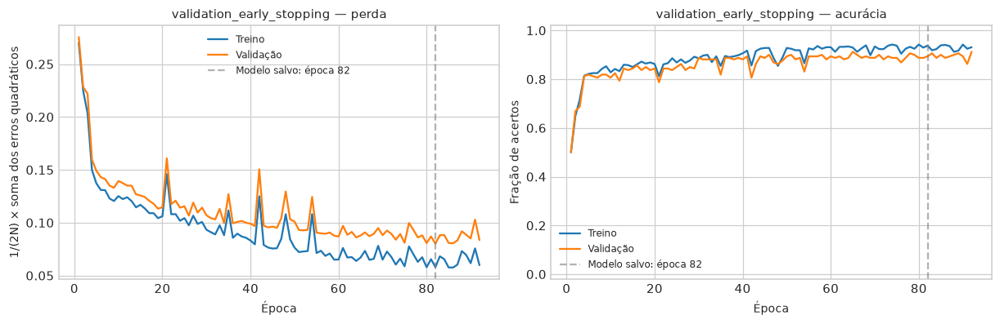

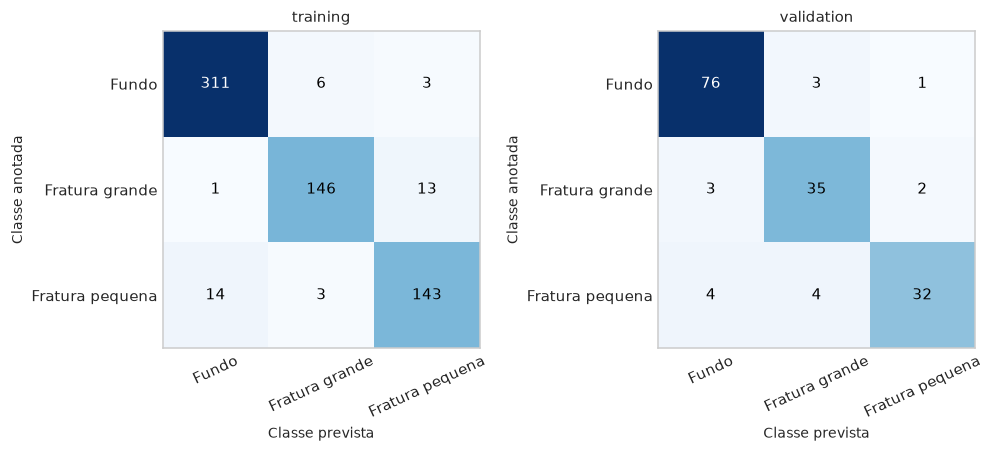

Classificação: 512/446,489 centros
Classificação: 89,600/446,489 centros
Classificação: 178,688/446,489 centros
Classificação: 267,776/446,489 centros
Classificação: 356,864/446,489 centros
Classificação: 445,952/446,489 centros
Classificação: 446,489/446,489 centros


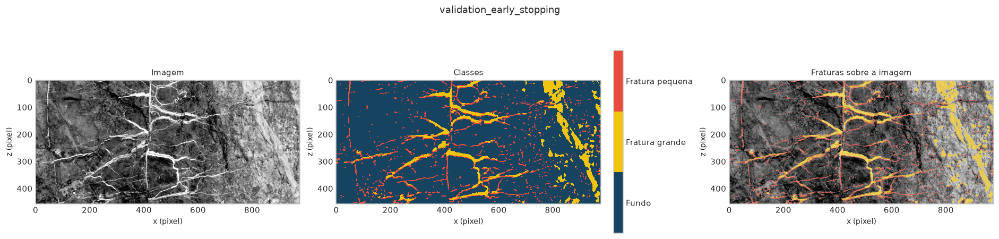

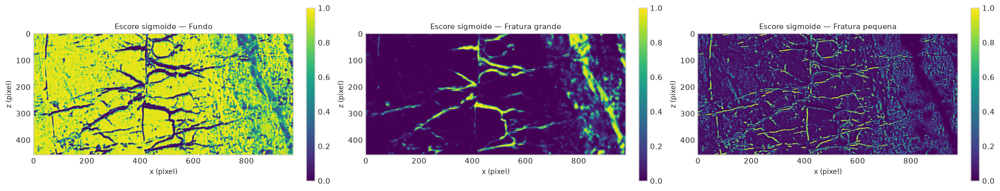

,subset,samples,loss,accuracy,precision_macro,recall_macro,f1_macro,task,experiment,parameters,epochs_run,selected_epoch,train_seconds,inference_seconds,inference_stride
0,training,640,0.0579729,0.9375,0.931765,0.926042,0.928795,multiclass,validation_early_stopping,2871,92,82,5.37676,2.2686,1
1,validation,160,0.080184,0.89375,0.887761,0.875,0.879836,multiclass,validation_early_stopping,2871,92,82,5.37676,2.2686,1


,subset,label,class,support,precision,recall,f1
0,training,0,Fundo,320,0.953988,0.971875,0.962848
1,training,1,Fratura grande,160,0.941935,0.9125,0.926984
2,training,2,Fratura pequena,160,0.899371,0.89375,0.896552
3,validation,0,Fundo,80,0.915663,0.95,0.932515
4,validation,1,Fratura grande,40,0.833333,0.875,0.853659
5,validation,2,Fratura pequena,40,0.914286,0.8,0.853333


,experiment,label,class,centers,fraction,inference_stride
0,validation_early_stopping,0,Fundo,376231,0.842643,1
1,validation_early_stopping,1,Fratura grande,36561,0.0818856,1
2,validation_early_stopping,2,Fratura pequena,33697,0.0754711,1


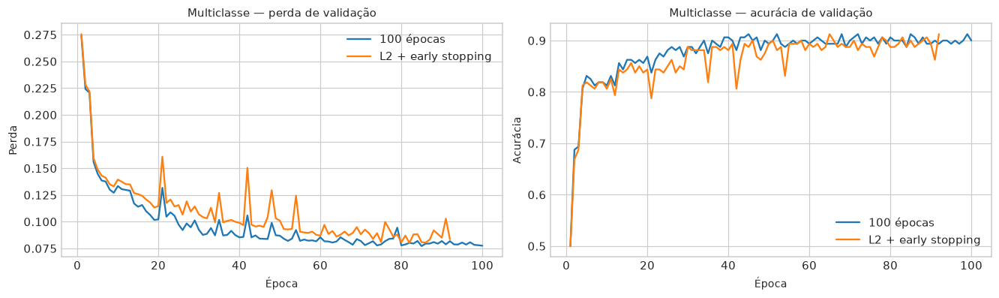

In [21]:
multiclass_controlled = run_multiclass(
    "validation_early_stopping",
    config=replace(multiclass_config, epochs=LONG_EPOCHS, weight_decay=1e-3,
                   patience=10, restore_best=True), split=True,
)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), constrained_layout=True)
for result, name in [(multiclass_validation, "100 épocas"), (multiclass_controlled, "L2 + early stopping")]:
    axes[0].plot(result.history.epoch, result.history.validation_loss, label=name)
    axes[1].plot(result.history.epoch, result.history.validation_accuracy, label=name)
axes[0].set(title="Multiclasse — perda de validação", xlabel="Época", ylabel="Perda")
axes[1].set(title="Multiclasse — acurácia de validação", xlabel="Época", ylabel="Acurácia")
for ax in axes:
    ax.legend()
fig.savefig(multiclass_dir / "validation_comparison.png", dpi=160)
plt.show()

#### 6.5.1. Interpretação — L2 e parada antecipada no problema multiclasse

O treino termina na época **92** e restaura os pesos da época **82**.
As perdas do modelo selecionado são **0,057973 no treino e 0,080184 na
validação**; as acurácias, **93,75% e 89,375%**. A lacuna treino/validação
é menor que no modelo sem regularização, mas acompanha a redução dos dois
desempenhos, não uma melhora na validação.

| Subconjunto | Classe | n | Precisão (%) | Recall (%) | F1 (%) |
|---|---|---:|---:|---:|---:|
| Treino | Fundo | 320 | 95,40 | 97,19 | 96,28 |
| Treino | Fratura grande | 160 | 94,19 | 91,25 | 92,70 |
| Treino | Fratura pequena | 160 | 89,94 | 89,38 | 89,66 |
| Treino | **Média macro** | 640 | **93,18** | **92,60** | **92,88** |
| Validação | Fundo | 80 | 91,57 | 95,00 | 93,25 |
| Validação | Fratura grande | 40 | 83,33 | 87,50 | 85,37 |
| Validação | Fratura pequena | 40 | 91,43 | 80,00 | 85,33 |
| Validação | **Média macro** | 160 | **88,78** | **87,50** | **87,98** |

A matriz de treino é `[[311, 6, 3], [1, 146, 13], [14, 3, 143]]`.
Na validação, **`[[76, 3, 1], [3, 35, 2], [4, 4, 32]]`** soma 17 erros:
**4 falsos positivos de detecção, 7 omissões e 6 trocas de tipo**. Sem
regularização eram 16 erros e 5 trocas. Reunindo grandes e pequenas, ambos
têm a mesma matriz de validação binária, `[[76, 4], [7, 73]]`; a piora
multiclasse corresponde a uma grande fratura adicional prevista como pequena.
O F1 macro cai de 88,80% para **87,98%**.

A menor perda não seleciona necessariamente a maior acurácia. Na época 92,
a acurácia de validação é **91,25%**, acima dos 89,375% da época restaurada,
mas a perda é pior, **0,083583**. A escolha da época 82 segue o critério
definido, que considera escores e intensidade dos erros, não somente argmax.
Uma prioridade operacional em F1 ou acurácia exigiria definir a seleção de
acordo com esse objetivo antes de avaliar o resultado.

O mapa contém **36.561 pixels grandes (8,19%)**, **33.697 pequenos (7,55%)**
e 84,26% de fundo. A área positiva, **15,74%**, supera os 14,45% anteriores.
Na direita, a classe grande cresce de 7,62% para **14,80%** da faixa, com
reaparecimento de respostas texturais. A margem inferior a 0,1 aumenta de
2,68% para **3,80%**. Considero que esse controle não melhorou a coerência
espacial nem a separação das classes nesta execução.

Foram **2.944 atualizações**, 8% menos que as 3.200 sem parada, com **5,377 s
de treino e 2,269 s de inferência**. A economia é modesta, e a alteração
conjunta de L2 e parada não permite isolar suas contribuições. Os resultados
não invalidam as técnicas, mas mostram que sua inclusão sem ajuste e ablação
não garante ganho.

### 6.6. Coleta dos resultados multiclasse

O resumo reúne os experimentos multiclasse e identifica os subconjuntos de treino
e validação. As interpretações anteriores distinguem erros de detecção e trocas
de tipo, além de examinar a coerência dos mapas e os escores das três saídas.

In [22]:
multiclass_summary, multiclass_distribution = save_section_summary(multiclass_results, multiclass_dir)
print(f"Resultados multiclasse: {multiclass_dir}")

,subset,samples,loss,accuracy,precision_macro,recall_macro,f1_macro,task,experiment,parameters,epochs_run,selected_epoch,train_seconds,inference_seconds,inference_stride
0,training,800,0.113905,0.85375,0.848175,0.834167,0.836968,multiclass,reference_10epochs,2871,10,10,0.690154,2.32012,1
1,training,800,0.108086,0.86375,0.858814,0.845,0.849757,multiclass,wider_10epochs,9339,10,10,0.758924,2.48548,1
2,training,800,0.0314995,0.96875,0.969211,0.958333,0.96338,multiclass,reference_100epochs,2871,100,100,7.09055,2.36263,1
3,training,640,0.0301855,0.967187,0.966224,0.957292,0.961552,multiclass,validation_100epochs,2871,100,100,5.82313,2.35966,1
4,validation,160,0.0775226,0.9,0.895697,0.883333,0.887966,multiclass,validation_100epochs,2871,100,100,5.82313,2.35966,1
5,training,640,0.0579729,0.9375,0.931765,0.926042,0.928795,multiclass,validation_early_stopping,2871,92,82,5.37676,2.2686,1
6,validation,160,0.080184,0.89375,0.887761,0.875,0.879836,multiclass,validation_early_stopping,2871,92,82,5.37676,2.2686,1


,experiment,label,class,centers,fraction,inference_stride,task
0,reference_10epochs,0,Fundo,360476,0.807357,1,multiclass
1,reference_10epochs,1,Fratura grande,64276,0.143959,1,multiclass
2,reference_10epochs,2,Fratura pequena,21737,0.0486843,1,multiclass
3,wider_10epochs,0,Fundo,370764,0.830399,1,multiclass
4,wider_10epochs,1,Fratura grande,48950,0.109633,1,multiclass
5,wider_10epochs,2,Fratura pequena,26775,0.0599679,1,multiclass
6,reference_100epochs,0,Fundo,389559,0.872494,1,multiclass
7,reference_100epochs,1,Fratura grande,20024,0.0448477,1,multiclass
8,reference_100epochs,2,Fratura pequena,36906,0.0826583,1,multiclass
9,validation_100epochs,0,Fundo,381975,0.855508,1,multiclass


Resultados multiclasse: /mnt/c/Users/Lucas Torres/Documents/Acadêmico/Doutorado/Tópicos Especiais em Processamento Inteligente da Informação/exercise04/results/main/multiclass


## 7. Coleta consolidada e preservação das anotações

Os arquivos `summary.csv` e `map_summary.csv` de `results/main/` reúnem os dois
problemas, identificados pela coluna `task`. Cada bloco também possui seus próprios
resumos e subpastas por experimento. A execução desta seção consolida os resultados
já exportados, permitindo manter os blocos independentes.

Em cada experimento, `maps.npz` contém rótulos, escores, eixos `x,z` e stride;
`labels.png` armazena os IDs das classes, e `classification.png` apresenta a imagem
com o mapa e a sobreposição. Também são gravados os históricos, matrizes de confusão,
métricas por classe, pesos e configurações. Os resultados podem ser sobrescritos.

O SHA-256 dos CSVs originais é conferido novamente ao final para verificar que
o picking foi preservado durante toda a execução.

In [23]:
section_summaries = []
section_distributions = []
for task in ("binary", "multiclass"):
    directory = RUN_DIR / task
    summary_path = directory / "summary.csv"
    distribution_path = directory / "map_summary.csv"
    if summary_path.exists() and distribution_path.exists():
        section_summaries.append(pd.read_csv(summary_path))
        section_distributions.append(pd.read_csv(distribution_path))
if section_summaries:
    summary = pd.concat(section_summaries, ignore_index=True)
    distribution = pd.concat(section_distributions, ignore_index=True)
    summary.to_csv(RUN_DIR / "summary.csv", index=False)
    distribution.to_csv(RUN_DIR / "map_summary.csv", index=False)
    display(summary)
    display(distribution)
for key, path in ANNOTATION_PATHS.items():
    assert sha256(path.read_bytes()).hexdigest() == annotation_hashes[key],         f"O conteúdo de {path.name} mudou durante a execução."
print("Integridade confirmada: annotations_big.csv e annotations_small.csv preservados.")
print(f"Resultados disponíveis em: {RUN_DIR}")

,subset,samples,loss,accuracy,precision_macro,recall_macro,f1_macro,task,experiment,parameters,epochs_run,selected_epoch,train_seconds,inference_seconds,inference_stride
0,training,800,0.0740609,0.9025,0.905787,0.9025,0.902302,binary,reference_10epochs,2570,10,10,1.32418,2.40139,1
1,training,400,0.0517075,0.9375,0.938037,0.9375,0.937481,binary,manual_big_10epochs,2570,10,10,0.375149,2.33865,1
2,training,400,0.0969489,0.87,0.883857,0.87,0.868816,binary,manual_small_10epochs,2570,10,10,0.376632,2.28659,1
3,training,800,0.0758453,0.90375,0.908037,0.90375,0.903497,binary,wider_10epochs,8738,10,10,0.744594,2.42874,1
4,training,800,0.0146787,0.985,0.985194,0.985,0.984998,binary,reference_100epochs,2570,100,100,6.98198,2.31113,1
5,training,640,0.0122466,0.989062,0.989105,0.989062,0.989062,binary,validation_100epochs,2570,100,100,5.82107,2.42732,1
6,validation,160,0.0431002,0.95625,0.958039,0.95625,0.956207,binary,validation_100epochs,2570,100,100,5.82107,2.42732,1
7,training,640,0.0328501,0.970313,0.97109,0.970312,0.9703,binary,validation_early_stopping,2570,95,85,5.54557,2.27132,1
8,validation,160,0.0636195,0.93125,0.934577,0.93125,0.931118,binary,validation_early_stopping,2570,95,85,5.54557,2.27132,1
9,training,800,0.113905,0.85375,0.848175,0.834167,0.836968,multiclass,reference_10epochs,2871,10,10,0.690154,2.32012,1


,experiment,label,class,centers,fraction,inference_stride,task
0,reference_10epochs,0,Fundo,375093,0.840095,1,binary
1,reference_10epochs,1,Fratura,71396,0.159905,1,binary
2,manual_big_10epochs,0,Fundo,390951,0.875612,1,binary
3,manual_big_10epochs,1,Fratura,55538,0.124388,1,binary
4,manual_small_10epochs,0,Fundo,408303,0.914475,1,binary
5,manual_small_10epochs,1,Fratura,38186,0.0855251,1,binary
6,wider_10epochs,0,Fundo,383547,0.859029,1,binary
7,wider_10epochs,1,Fratura,62942,0.140971,1,binary
8,reference_100epochs,0,Fundo,383198,0.858247,1,binary
9,reference_100epochs,1,Fratura,63291,0.141753,1,binary


Integridade confirmada: annotations_big.csv e annotations_small.csv preservados.
Resultados disponíveis em: /mnt/c/Users/Lucas Torres/Documents/Acadêmico/Doutorado/Tópicos Especiais em Processamento Inteligente da Informação/exercise04/results/main


### 7.1. Diagnósticos reproduzíveis para a interpretação e a comparação

A célula seguinte lê as saídas existentes, sem treinar novamente nem alterar
as anotações. Os diagnósticos são gravados em `results/main/analysis/`.

Na comparação de detecção, os rótulos multiclasse 1 e 2 são reunidos **após
o argmax**, sem somar sigmoides ou ajustar limiares. A concordância e a IoU
comparam **duas previsões**, não uma previsão com verdade de terreno.
A comparação nos centros comuns de validação considera somente os pontos
reservados por ambos, pois as duas estratificações não escolhem os mesmos
positivos. A figura final localiza as diferenças entre os modelos base
de 100 épocas. Esses diagnósticos subsidiam a conclusão comparativa.

score_margins


,task,experiment,mean_score_margin,fraction_margin_lt_0.1
0,binary,manual_big_10epochs,0.83605,0.0168918
1,binary,manual_small_10epochs,0.752014,0.0273982
2,binary,reference_100epochs,0.892587,0.0124102
3,binary,reference_10epochs,0.741071,0.0377725
4,binary,validation_100epochs,0.852703,0.0160877
5,binary,validation_early_stopping,0.751444,0.0310243
6,binary,wider_10epochs,0.794178,0.0371207
7,multiclass,reference_100epochs,0.85682,0.0267599
8,multiclass,reference_10epochs,0.697596,0.0538132
9,multiclass,validation_100epochs,0.851128,0.0267621


patch_overlap


,task,experiment,validation_centers,centers_with_overlapping_training_patch,overlap_fraction
0,binary,validation_100epochs,160,131,0.81875
1,binary,validation_early_stopping,160,131,0.81875
2,multiclass,validation_100epochs,160,131,0.81875
3,multiclass,validation_early_stopping,160,131,0.81875


multiclass_errors_and_collapsed_metrics


,experiment,subset,wrong_fracture_type,samples,tn,fp,fn,tp,accuracy,precision_fracture,recall_fracture,f1_fracture
0,reference_100epochs,training,12,800,400,0,13,387,0.98375,1,0.9675,0.983482
1,reference_10epochs,training,34,800,365,35,48,352,0.89625,0.909561,0.88,0.894536
2,validation_100epochs,training,10,640,319,1,10,310,0.982812,0.996785,0.96875,0.982567
3,validation_100epochs,validation,5,160,76,4,7,73,0.93125,0.948052,0.9125,0.929936
4,validation_early_stopping,training,16,640,311,9,15,305,0.9625,0.971338,0.953125,0.962145
5,validation_early_stopping,validation,6,160,76,4,7,73,0.93125,0.948052,0.9125,0.929936
6,wider_10epochs,training,27,800,368,32,50,350,0.8975,0.91623,0.875,0.895141


binary_multiclass_maps


,experiment,binary_fracture_fraction,multiclass_fracture_fraction,map_agreement,prediction_iou,pixels_only_binary,pixels_only_multiclass
0,reference_10epochs,0.159905,0.192643,0.938532,0.703063,6414,21031
1,wider_10epochs,0.140971,0.169601,0.952767,0.735985,4153,16936
2,reference_100epochs,0.141753,0.127506,0.954321,0.709919,13378,7017
3,validation_100epochs,0.152512,0.144492,0.934043,0.636562,16515,12934
4,validation_early_stopping,0.132075,0.157357,0.943569,0.673678,6954,18242


common_validation


,experiment,task,background_support,fracture_support,samples,tn,fp,fn,tp,accuracy,precision_fracture,recall_fracture,f1_fracture
0,validation_100epochs,binary,80,15,95,79,1,3,12,0.957895,0.923077,0.8,0.857143
1,validation_100epochs,multiclass_collapsed,80,15,95,76,4,3,12,0.926316,0.75,0.8,0.774194
2,validation_early_stopping,binary,80,15,95,78,2,3,12,0.947368,0.857143,0.8,0.827586
3,validation_early_stopping,multiclass_collapsed,80,15,95,76,4,3,12,0.926316,0.75,0.8,0.774194


Diagnósticos calculados a partir das saídas existentes: /mnt/c/Users/Lucas Torres/Documents/Acadêmico/Doutorado/Tópicos Especiais em Processamento Inteligente da Informação/exercise04/results/main/analysis


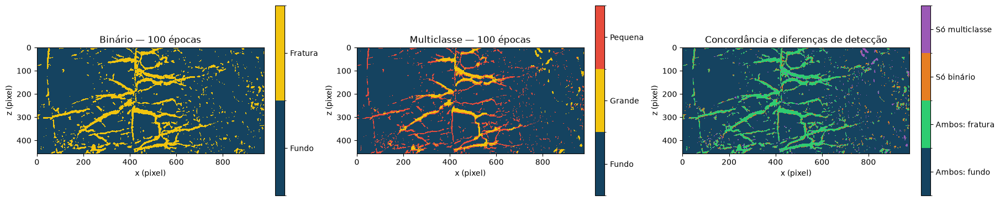

In [2]:
from scipy.spatial import cKDTree

analysis_dir = RUN_DIR / "analysis"
analysis_dir.mkdir(parents=True, exist_ok=True)
analysis_experiments = (
    "reference_10epochs", "wider_10epochs", "reference_100epochs",
    "validation_100epochs", "validation_early_stopping",
)
analysis_scores, analysis_regions, analysis_overlap, analysis_history = [], [], [], []
analysis_error_types, analysis_comparison, analysis_common_validation = [], [], []


def collapsed_binary_metrics(matrix):
    """Matriz 2 × 2 após reunir os IDs de fratura, sem alterar os modelos."""
    tn, fp, fn, tp = matrix.ravel()
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return {
        "samples": int(matrix.sum()), "tn": int(tn), "fp": int(fp),
        "fn": int(fn), "tp": int(tp), "accuracy": float((tn + tp) / matrix.sum()),
        "precision_fracture": float(precision), "recall_fracture": float(recall),
        "f1_fracture": float(2 * precision * recall / (precision + recall))
        if precision + recall else 0.0,
    }


for task in ("binary", "multiclass"):
    for directory in sorted((RUN_DIR / task).iterdir()):
        if not directory.is_dir() or not (directory / "maps.npz").exists():
            continue
        history = pd.read_csv(directory / "history.csv")
        config = json.loads((directory / "config.json").read_text())
        annotations = pd.read_csv(directory / "annotations.csv")
        row = {"task": task, "experiment": directory.name,
               "epochs_run": config["epochs_run"], "selected_epoch": config["selected_epoch"],
               "min_train_loss_epoch": int(history.loc[history.train_loss.idxmin(), "epoch"]),
               "min_train_loss": float(history.train_loss.min())}
        if "validation_loss" in history:
            row["min_validation_loss_epoch"] = int(history.loc[history.validation_loss.idxmin(), "epoch"])
            row["min_validation_loss"] = float(history.validation_loss.min())
        analysis_history.append(row)
        with np.load(directory / "maps.npz") as saved:
            predicted, scores = saved["labels"], saved["scores"]
            ordered = np.sort(scores, axis=-1)
            margin = ordered[:, :, -1] - ordered[:, :, -2]
            analysis_scores.append({
                "task": task, "experiment": directory.name,
                "mean_score_margin": float(margin.mean()),
                "fraction_margin_lt_0.1": float((margin < 0.1).mean()),
            })
            for region, columns in (("left_x_lt_320", slice(0, 320)),
                                    ("center_320_to_699", slice(320, 700)),
                                    ("right_x_ge_700", slice(700, None))):
                analysis_regions.append({
                    "task": task, "experiment": directory.name, "region": region,
                    "predicted_fracture_fraction": float((predicted[:, columns] > 0).mean()),
                })
        if set(annotations.subset) == {"training", "validation"}:
            training_xy = annotations[annotations.subset == "training"][["x", "z"]].to_numpy()
            validation_xy = annotations[annotations.subset == "validation"][["x", "z"]].to_numpy()
            distances, _ = cKDTree(training_xy).query(validation_xy, p=np.inf)
            # Dois recortes 17 × 17 compartilham pixels se |dx| e |dz| forem <= 16.
            analysis_overlap.append({
                "task": task, "experiment": directory.name,
                "validation_centers": len(validation_xy),
                "centers_with_overlapping_training_patch": int((distances <= 16).sum()),
                "overlap_fraction": float((distances <= 16).mean()),
            })
        if task == "multiclass":
            for path in directory.glob("confusion_*.csv"):
                confusion = pd.read_csv(path, index_col=0).to_numpy()
                collapsed = np.array([
                    [confusion[0, 0], confusion[0, 1:].sum()],
                    [confusion[1:, 0].sum(), confusion[1:, 1:].sum()],
                ])
                analysis_error_types.append({
                    "experiment": directory.name, "subset": path.stem.removeprefix("confusion_"),
                    "wrong_fracture_type": int(confusion[1, 2] + confusion[2, 1]),
                    **collapsed_binary_metrics(collapsed),
                })

for name in analysis_experiments:
    binary_path, multi_path = RUN_DIR / "binary" / name, RUN_DIR / "multiclass" / name
    with np.load(binary_path / "maps.npz") as saved:
        binary_mask = saved["labels"] > 0
    with np.load(multi_path / "maps.npz") as saved:
        multi_mask = saved["labels"] > 0
    intersection, union = int((binary_mask & multi_mask).sum()), int((binary_mask | multi_mask).sum())
    analysis_comparison.append({
        "experiment": name,
        "binary_fracture_fraction": float(binary_mask.mean()),
        "multiclass_fracture_fraction": float(multi_mask.mean()),
        "map_agreement": float((binary_mask == multi_mask).mean()),
        "prediction_iou": intersection / union if union else 1.0,
        "pixels_only_binary": int((binary_mask & ~multi_mask).sum()),
        "pixels_only_multiclass": int((multi_mask & ~binary_mask).sum()),
    })
    if name.startswith("validation"):
        binary_points = pd.read_csv(binary_path / "annotations.csv")
        multi_points = pd.read_csv(multi_path / "annotations.csv")
        common_points = binary_points[binary_points.subset == "validation"][["x", "z", "label"]].merge(
            multi_points[multi_points.subset == "validation"][["x", "z"]], on=["x", "z"]
        )
        x, z = common_points.x.to_numpy(), common_points.z.to_numpy()
        truth = common_points.label.to_numpy()
        for task, mask in (("binary", binary_mask), ("multiclass_collapsed", multi_mask)):
            matrix = np.zeros((2, 2), dtype=int)
            np.add.at(matrix, (truth, mask[z, x].astype(int)), 1)
            analysis_common_validation.append({
                "experiment": name, "task": task,
                "background_support": int((truth == 0).sum()),
                "fracture_support": int((truth == 1).sum()),
                **collapsed_binary_metrics(matrix),
            })

analysis_tables = {
    "score_margins": pd.DataFrame(analysis_scores),
    "regional_predictions": pd.DataFrame(analysis_regions),
    "patch_overlap": pd.DataFrame(analysis_overlap),
    "history_selection": pd.DataFrame(analysis_history),
    "multiclass_errors_and_collapsed_metrics": pd.DataFrame(analysis_error_types),
    "binary_multiclass_maps": pd.DataFrame(analysis_comparison),
    "common_validation": pd.DataFrame(analysis_common_validation),
}
for name, table in analysis_tables.items():
    table.to_csv(analysis_dir / f"{name}.csv", index=False)
for name in ("score_margins", "patch_overlap", "multiclass_errors_and_collapsed_metrics",
             "binary_multiclass_maps", "common_validation"):
    print(name)
    display(analysis_tables[name])
print(f"Diagnósticos calculados a partir das saídas existentes: {analysis_dir}")

# Comparação visual dos modelos base de 100 épocas, sem alterar suas previsões.
with np.load(RUN_DIR / "binary/reference_100epochs/maps.npz") as saved:
    comparison_binary_labels = saved["labels"]
with np.load(RUN_DIR / "multiclass/reference_100epochs/maps.npz") as saved:
    comparison_multi_labels = saved["labels"]
comparison_binary_mask = comparison_binary_labels > 0
comparison_multi_mask = comparison_multi_labels > 0
comparison_disagreement = np.zeros(comparison_binary_labels.shape, dtype=np.uint8)
comparison_disagreement[comparison_binary_mask & comparison_multi_mask] = 1
comparison_disagreement[comparison_binary_mask & ~comparison_multi_mask] = 2
comparison_disagreement[~comparison_binary_mask & comparison_multi_mask] = 3
fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
for ax, values, title, colors, names in (
    (axes[0], comparison_binary_labels, "Binário — 100 épocas",
     ["#154360", "#f1c40f"], ["Fundo", "Fratura"]),
    (axes[1], comparison_multi_labels, "Multiclasse — 100 épocas",
     ["#154360", "#f1c40f", "#e74c3c"], ["Fundo", "Grande", "Pequena"]),
    (axes[2], comparison_disagreement, "Concordância e diferenças de detecção",
     ["#154360", "#2ecc71", "#e67e22", "#9b59b6"],
     ["Ambos: fundo", "Ambos: fratura", "Só binário", "Só multiclasse"]),
):
    plotted = ax.imshow(values, cmap=ListedColormap(colors),
                        norm=BoundaryNorm(np.arange(len(colors) + 1) - 0.5, len(colors)),
                        interpolation="nearest")
    ax.set(title=title, xlabel="x (pixel)", ylabel="z (pixel)")
    ax.grid(False)
    colorbar = fig.colorbar(plotted, ax=ax, ticks=range(len(colors)), shrink=0.7)
    colorbar.ax.set_yticklabels(names)
fig.savefig(analysis_dir / "comparison_100epochs.png", dpi=160)
plt.show()


## 8. Conclusão

### 8.1. Síntese dos experimentos e da aplicação

A CNN aprendeu padrões locais associados às fraturas anotadas e produziu mapas
que acompanham parte importante das estruturas visíveis na imagem de rocha.
O comportamento é relevante como apoio à identificação de fraturas em um
problema de interesse geofísico, reduzindo o trabalho de inspeção pixel a pixel.
Entretanto, a qualidade depende da seleção das amostras, do orçamento de treino
e do objetivo de classificação. Traços reconhecíveis não tornam o mapa uma
descrição física validada da rocha.

Na **questão 1**, as seleções mostraram especializações diferentes. O modelo
`big` ajustou melhor seus próprios pontos, com acurácia 93,75% e F1 positivo
93,64%, mas omitiu traços finos e marcou extensas texturas à direita. O modelo
`small` teve acurácia 87,00% e F1 positivo 85,64%, recuperou mais ramificações
finas e reduziu as manchas, porém omitiu 22,50% das fraturas de seu conjunto.
Os mapas evidenciam a influência do picking, incluindo os fundos selecionados;
as métricas em conjuntos distintos não estabelecem qual seleção generaliza
melhor. A concatenação aproveita as duas fontes sem novo picking.

Na **questão 2**, ampliar a rede trouxe pouco ganho no binário: um acerto
adicional em 800 pontos, apesar de 3,40 vezes mais parâmetros. No multiclasse,
foram oito acertos adicionais, concentrados na redução de trocas de tipo,
com 3,25 vezes mais parâmetros. As redes maiores mantiveram a sensibilidade
à textura de fundo. Nesta execução, considero o ganho insuficiente para
preferir a ampliação ao modelo base com o mesmo orçamento.

Na **questão 3**, aumentar de 10 para 100 épocas produziu o ganho mais
consistente: a acurácia binária passou de 90,25% para 98,50% e a multiclasse
de 85,375% para 96,875%. Os mapas reduziram respostas texturais à direita e
acompanharam melhor os traços principais. Com validação sem regularização,
as acurácias foram 95,625% e 90,00%. Não houve colapso por excesso de épocas:
no binário, a melhor perda reservada ocorreu na época 100; no multiclasse,
houve um patamar e pequena piora em relação ao mínimo da época 85.

L2 com parada antecipada não melhorou os resultados reservados: as acurácias
foram 93,125% e 89,375%, com economia de apenas 5% e 8% das atualizações.
Uma lacuna menor entre treino e validação não significa, isoladamente, melhor
generalização. A avaliação não invalida essas técnicas, mas não sustenta a
configuração conjunta escolhida como melhoria desta execução.

### 8.2. Comparação quantitativa entre binário e multiclasse

O binário responde se um ponto é fratura; o multiclasse também distingue
grandes e pequenas. Na **questão 4**, a menor acurácia multiclasse incorpora
essa dificuldade adicional. Para separar os efeitos, a tabela compara os
mesmos 800 centros de treinamento, reunindo as classes positivas **após o
argmax multiclasse**, sem somar sigmoides ou ajustar limiares:

| Configuração — treino nos 800 pontos | Acurácia binária (%) | Acurácia multiclasse, 3 classes (%) | Multiclasse reunida em fratura/fundo (%) |
|---|---:|---:|---:|
| Base, 10 épocas | 90,250 | 85,375 | 89,625 |
| Ampliada, 10 épocas | 90,375 | 86,375 | 89,750 |
| Base, 100 épocas | 98,500 | 96,875 | 98,375 |

Após reunir as classes, a diferença cai para **0,625 ponto percentual** nos
dois modelos de 10 épocas e **0,125 ponto** nos de 100 épocas. Neste último
caso, os 25 erros multiclasse incluem 12 trocas de tipo e 13 omissões; o
binário tem 12 erros, dois falsos positivos e dez omissões. Portanto, uma
parte importante da diferença entre os problemas decorre da distinção de
tipo, e não de uma perda equivalente na capacidade de detectar fraturas.

Nos conjuntos próprios de validação, o multiclasse sem regularização tem
90,00% de acurácia em três classes e **93,125%** após a reunião, contra
95,625% do binário. A estratificação por duas ou três classes, porém, não
reserva os mesmos positivos. A interseção possui **95 centros: 80 fundos
e somente 15 fraturas**. Nesse conjunto comum, o binário sem regularização
acerta **91/95 (95,79%)**, e o multiclasse reunido, **88/95 (92,63%)**.
Ambos recuperam 12 das 15 fraturas; a diferença está em um versus quatro
fundos previstos como fratura. Com regularização, são 90/95 e 88/95.
Essa comparação favorece o binário nesta amostra, mas os poucos positivos
e a dependência espacial impedem uma conclusão geral de superioridade.

As pequenas fraturas são o principal limite multiclasse: recall de 71,00%
na base, 74,00% na ampliada e 94,50% no treino de 100 épocas, mas apenas
**80,00% na validação**, com ou sem o controle empregado. O fundo possui
maior suporte e não deve mascarar essa dificuldade; a análise por classe
e o F1 macro são necessários além da acurácia global. Os valores absolutos
da perda de duas e três saídas também não constituem uma comparação direta
de dificuldade, pois a função soma termos em dimensões diferentes.

### 8.3. Comparação qualitativa e concordância dos mapas

O binário oferece uma indicação única, mais simples para triagem. O multiclasse
acrescenta informação sobre padrões aprendidos como grandes ou pequenos, mas
introduz alternância de rótulos ao longo de um mesmo traço. Essas definições
vêm do picking visual, sem uma medida geométrica formal de espessura.
Na minha avaliação, a distinção adicional é útil como hipótese de classificação
local, mas ainda não identifica tipos físicos de fratura de forma consistente.

| Configuração | Pixels positivos binários (%) | Grandes + pequenas no multiclasse (%) | Concordância das máscaras (%) | IoU entre previsões (%) |
|---|---:|---:|---:|---:|
| Base, 10 épocas | 15,99 | 19,26 | 93,85 | 70,31 |
| Ampliada, 10 épocas | 14,10 | 16,96 | 95,28 | 73,60 |
| Base, 100 épocas | 14,18 | 12,75 | 95,43 | 70,99 |
| Validação, 100 épocas | 15,25 | 14,45 | 93,40 | 63,66 |
| Validação, L2 + parada | 13,21 | 15,74 | 94,36 | 67,37 |

A concordância de 93% a 95% é influenciada pela predominância de fundo.
A IoU das regiões positivas, de aproximadamente 64% a 74%, mostra diferenças
mais expressivas de localização. Essas medidas comparam **duas previsões**,
não correção contra uma máscara de referência. Nos modelos de 100 épocas,
**13.378 pixels** são positivos somente no binário e **7.017** somente no
multiclasse. Boa acurácia nos pontos e áreas positivas próximas não tornam
os mapas equivalentes.

Os modelos base de 100 épocas treinados nos 800 pontos parecem mais coerentes
com os traços visíveis que os de 10 épocas: reduzem as manchas à direita e
recuperam melhor a rede central. Persistem interrupções, espessamento e
conexões locais discutíveis. O multiclasse também pode dar rótulos diferentes
às bordas e ao interior de uma estrutura. Um mapa mais esparso não é
necessariamente melhor: a área deve ser examinada junto ao recall e à
continuidade. Margens maiores entre escores também não garantem correção.

### 8.4. Custo, limites e escolha para a aplicação

A saída multiclasse acrescenta **301 parâmetros**, de 2.570 para 2.871,
aumento de **11,71%**. O custo permanece próximo: os treinos completos de
100 épocas levaram 6,982 s no binário e 7,091 s no multiclasse; as inferências,
2,311 s e 2,363 s. As convoluções são iguais e a diferença está na saída,
de modo que a classe adicional não apresentou grande impacto nesta imagem.
São medições únicas na RX 9070 XT, sem benchmark que confirme diferenças pequenas.

Para uma primeira indicação de onde há fraturas, eu priorizaria a formulação
binária e a arquitetura base com orçamento de treinamento suficiente. Ela
apresentou melhor validação interna e dispensa uma distinção de tipo ainda
espacialmente ambígua. Quando a aplicação exigir separar os padrões de grandes
e pequenas, considero o multiclasse uma extensão útil, de baixo custo adicional,
com revisão específica das pequenas fraturas e da consistência dos rótulos.

As conclusões se restringem a uma imagem, um picking e uma semente por
arquitetura. Os 800 centros são distintos, mas os recortes são correlacionados:
**81,88% dos patches de validação se sobrepõem a patches de treino** nos
dois problemas. A seleção também utiliza essa mesma validação, sem teste
final independente. Não há estimativa de generalização para novas imagens
nem validação geofísica completa. Os próximos passos para sustentar a aplicação
são avaliação espacialmente separada ou em outras imagens, repetição com
sementes distintas, definição mais objetiva das classes de tamanho e inspeção
com referência adequada. Os resultados sustentam a CNN como ferramenta de
apoio à identificação, acompanhada de revisão dos mapas e de avaliação que
considere as limitações do conjunto anotado.